<a href="https://colab.research.google.com/github/laiajufresa-code/TFG/blob/main/TFG_LLIBRETA4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLIBRETA 4 · Escenaris de dades segons el circuit assistencial

**Objectiu:** quantificar **quanta informació aporta cada font de dades** per classificar el nivell de risc (Low, Moderate, High, Critical), simulant les situacions reals del seguiment de la diabetis: la consulta, l'analítica, el smartwatch i el sensor continu de glucosa (CGM).

Es fa servir **exactament la mateixa metodologia que la Llibreta 3**: la mateixa partició 80/20, les mateixes 5 caixes, els mateixos 6 models, les mateixes graelles d'hiperparàmetres i les mateixes mètriques. **Només canvia la llista de variables** de cada escenari. Així, les diferències entre escenaris només es poden atribuir a les dades.

### Els 6 escenaris (de menys a més dades)

| | Escenari | Moment real del circuit | Variables |
|---|---|---|---|
| **E1** | Només smartwatch | App del pacient, sense accés a la història clínica | 11 |
| **E2** | Consulta sense analítica | Visita de control d'infermeria / telefònica, amb l'analítica antiga | 11 |
| **E3** | Consulta completa | Visita amb analítica recent (semestral al CAP o a l'hospital) | 13 |
| **E4** | Història clínica + smartwatch | Telemonitoratge entre visites **sense** CGM (majoria de tipus 2) | 22 |
| **E5** | Història clínica + smartwatch + CGM | Telemonitoratge **amb** CGM finançat (tipus 1 i tipus 2 amb insulina intensiva) | 25 |
| **E6** | Tot | Integració de totes les fonts (= Escenari A de la Llibreta 3) | 32 |

### Comparacions que responen les preguntes del TFG

| Comparació | Pregunta |
|---|---|
| E2 → E3 | Quant aporta l'analítica de sang? |
| **E2 → E4** | **Entre visites, el smartwatch millora el que ja sap el metge?** (pregunta central) |
| E4 → E5 | Quant aporta el CGM? |
| E1 vs E2 | Tots sols i amb les mateixes 11 variables: informa més el rellotge o la història clínica? |
| E3 vs E5 | Pot el telemonitoratge sense sang acostar-se a una visita amb analítica? |
| E5 → E6 | Què hi afegeixen l'analítica i les variables de recollida dubtosa? |

### Decisions metodològiques

1. **Escenaris definits per recursos, no pel tipus de diabetis.** El dataset no indica si cada pacient té diabetis tipus 1 o tipus 2. Cada escenari representa un nivell de dades disponibles dins del circuit assistencial actual i es pot aplicar a qualsevol pacient. Cal declarar-ho com a limitació.
2. **E4 i E5 inclouen la història clínica (E2)**, perquè en un telemonitoratge real el sistema ja coneix l'edat, la durada, la medicació, etc. Així, E2 → E4 aïlla exactament el que aporta el smartwatch.
3. **Variables de recollida dubtosa només a E6:** `glucose_postprandial_mg_dl` (depèn del glucòmetre), `medication_adherence_pct` (s'estima per dispensació de farmàcia), `previous_hypoglycemia_events` (record del pacient), `water_intake_l` i `carbohydrate_intake_g` (registre manual en una app).
4. **E6 es torna a calcular aquí** amb el mateix codi, i ha de coincidir amb l'Escenari A de la Llibreta 3 (control de reproductibilitat).
5. **Mètriques de seguretat del pacient:** a més de l'F1 macro (mètrica principal), es reporta la **sensibilitat de Critical i de High** de cada escenari (pacients greus que el model no detectaria).
6. **Comparacions amb interval de confiança:** les diferències entre escenaris es calculen sobre els **mateixos pacients del test** amb un *bootstrap* aparellat (1.000 remostrejos). Una diferència és significativa si el seu IC 95 % no inclou el 0.
7. **Desament automàtic:** els resultats de cada escenari es guarden en un fitxer (a Google Drive si està connectat). Si Colab es desconnecta, en tornar a executar es recuperen els escenaris ja fets i no cal tornar-los a entrenar.

**Temps aproximat:** entre 1 i 2 hores amb els 6 models (l'SVM és el més lent). Per anar més ràpid, a la Cel·la 2 es poden deixar només `Logistic Regression`, `Random Forest` i `XGBoost`.

### Estructura

| Bloc | Cel·les |
|---|---|
| 0 · Llibreries, paràmetres i definició dels escenaris | 1 – 3 |
| 1 · Variables, partició 80/20 i caixes (idèntiques a la Llibreta 3) | 4 |
| 2 · Models, mètriques i funció d'entrenament | 5 – 8 |
| 3 · Execució dels 6 escenaris | 9 – 14 |
| 4 · Comparativa entre escenaris i conclusions | 15 – 18 |

## BLOC 0 · Llibreries, paràmetres i escenaris
### Cel·la 1 · Llibreries i càrrega de les dades

In [19]:
import os, glob, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, cohen_kappa_score, precision_recall_fscore_support)
from xgboost import XGBClassifier
import sklearn, xgboost
import kagglehub

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)

path = kagglehub.dataset_download("colabsss/diabetes-risk-monitoring-dataset")
csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df_raw = pd.read_csv(csv_path)
print("Dades:", df_raw.shape, "· scikit-learn", sklearn.__version__, "· xgboost", xgboost.__version__)

Using Colab cache for faster access to the 'diabetes-risk-monitoring-dataset' dataset.
Dades: (15000, 35) · scikit-learn 1.6.1 · xgboost 3.4.1


### Cel·la 2 · Paràmetres (es canvien NOMÉS aquí)
- `MODELS_ACTIUS`: models que s'entrenen. Per defecte, els 6 de la Llibreta 3.
- `ESCENARIS_ACTIUS`: escenaris que s'executen (per si es vol repetir només un).
- `DESAR_A_DRIVE` / `REUTILITZAR`: desament automàtic dels resultats de cada escenari i recuperació si Colab es desconnecta. Si es canvia alguna graella o la llista de models, cal posar `REUTILITZAR = False` per tornar a entrenar.

In [2]:
# ======================= PARÀMETRES =======================
SEED       = 42          # mateixa llavor que la Llibreta 3 -> mateixa partició i mateixes caixes
TEST_SIZE  = 0.20
K_FOLDS    = 5
METRICA    = "f1_macro"
N_JOBS     = -1
MODE_RAPID = False       # True = graelles mínimes per provar el codi (NO per als resultats finals)
LLINDAR_SD_ESTABLE = 0.02

MODELS_ACTIUS    = ["Logistic Regression", "SVM", "KNN", "Naive Bayes", "Random Forest", "XGBoost"]
ESCENARIS_ACTIUS = ["E1", "E2", "E3", "E4", "E5", "E6"]

DESAR_A_DRIVE = True     # desa els resultats de cada escenari a Google Drive (si no, a la carpeta local de Colab)
REUTILITZAR   = True     # si ja existeix el fitxer d'un escenari, el carrega en lloc de tornar-lo a entrenar
N_BOOT        = 1000     # remostrejos del bootstrap aparellat per comparar escenaris
# ==========================================================

TARGET = "diabetes_risk_level"
ORDER  = ["Low_Risk", "Moderate_Risk", "High_Risk", "Critical_Risk"]
ETIQ   = ["Low", "Moderate", "High", "Critical"]
PAL4   = ["#2ca02c", "#f2c94c", "#f2994a", "#d62728"]
ID_COLS = ["patient_id", "monitoring_date"]
CAT_BIN = ["gender", "family_history_diabetes", "medication_change_recent"]

if DESAR_A_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CARPETA = "/content/drive/MyDrive/TFG_resultats"
    except Exception:
        print("No s'ha pogut connectar Google Drive -> es desa a la carpeta local")
        CARPETA = "resultats_llibreta4"
else:
    CARPETA = "resultats_llibreta4"
os.makedirs(CARPETA, exist_ok=True)
print("Carpeta de resultats:", CARPETA)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})
np.random.seed(SEED)

No s'ha pogut connectar Google Drive -> es desa a la carpeta local
Carpeta de resultats: resultats_llibreta4


### Cel·la 3 · Definició dels escenaris
Les 32 variables predictores es reparteixen en **5 blocs segons on es recullen** dins del circuit assistencial. Cada escenari és una combinació d'aquests blocs. La cel·la comprova que cada variable és exactament a un bloc i que entre tots sumen les 32.

In [3]:
BLOCS = {
    "Història clínica i consulta": ["age", "gender", "bmi", "family_history_diabetes", "diabetes_duration_years",
                                    "systolic_bp_mmhg", "diastolic_bp_mmhg", "insulin_dose_units",
                                    "medication_change_recent", "comorbidity_count", "outpatient_visits_6m"],
    "Analítica de sang":           ["hba1c_percent", "glucose_fasting_mg_dl"],
    "Smartwatch":                  ["heart_rate_bpm", "heart_rate_variability_ms", "spo2_percent", "body_temperature_c",
                                    "physical_activity_min", "step_count", "calories_burned", "sedentary_duration_hr",
                                    "sleep_duration_hr", "sleep_quality_score", "stress_level_score"],
    "CGM (sensor de glucosa)":     ["sensor_glucose_variability", "daily_monitoring_frequency", "abnormal_glucose_events"],
    "Recollida dubtosa":           ["glucose_postprandial_mg_dl", "medication_adherence_pct", "previous_hypoglycemia_events",
                                    "water_intake_l", "carbohydrate_intake_g"],
}
HCE, LAB, WATCH, CGM, DUBT = BLOCS.values()

PREDICTORES = [c for c in df_raw.columns if c not in ID_COLS + [TARGET]]
totes = sum(BLOCS.values(), [])
assert len(totes) == len(set(totes)) == 32 and set(totes) == set(PREDICTORES), "Els blocs no cobreixen exactament les 32 variables"

def ordenar(cols):                       # mateix ordre de columnes que el dataset original
    return [c for c in PREDICTORES if c in set(cols)]

ESCENARIS = {
    "E1": {"nom": "Només smartwatch",                    "circuit": "App del pacient, sense història clínica",              "vars": ordenar(WATCH)},
    "E2": {"nom": "Consulta sense analítica",            "circuit": "Visita de control / telefònica amb analítica antiga",  "vars": ordenar(HCE)},
    "E3": {"nom": "Consulta completa",                   "circuit": "Visita amb analítica recent",                          "vars": ordenar(HCE + LAB)},
    "E4": {"nom": "Història clínica + smartwatch",       "circuit": "Telemonitoratge entre visites sense CGM",              "vars": ordenar(HCE + WATCH)},
    "E5": {"nom": "Història clínica + smartwatch + CGM", "circuit": "Telemonitoratge entre visites amb CGM",                "vars": ordenar(HCE + WATCH + CGM)},
    "E6": {"nom": "Tot",                                 "circuit": "Integració de totes les fonts (= Escenari A, Llibreta 3)", "vars": list(PREDICTORES)},
}

taula_esc = pd.DataFrame({e: {"Escenari": d["nom"], "Circuit assistencial": d["circuit"], "Nº variables": len(d["vars"]),
                              **{b: "✔" if set(v) <= set(d["vars"]) else "" for b, v in BLOCS.items()}}
                          for e, d in ESCENARIS.items()}).T
display(taula_esc)
for e, d in ESCENARIS.items():
    print(f"{e} ({len(d['vars'])}): {', '.join(d['vars'])}")

,Escenari,Circuit assistencial,Nº variables,Història clínica i consulta,Analítica de sang,Smartwatch,CGM (sensor de glucosa),Recollida dubtosa
E1,Només smartwatch,"App del pacient, sense història clínica",11,,,✔,,
E2,Consulta sense analítica,Visita de control / telefònica amb analítica a...,11,✔,,,,
E3,Consulta completa,Visita amb analítica recent,13,✔,✔,,,
E4,Història clínica + smartwatch,Telemonitoratge entre visites sense CGM,22,✔,,✔,,
E5,Història clínica + smartwatch + CGM,Telemonitoratge entre visites amb CGM,25,✔,,✔,✔,
E6,Tot,"Integració de totes les fonts (= Escenari A, L...",32,✔,✔,✔,✔,✔


E1 (11): heart_rate_bpm, spo2_percent, body_temperature_c, physical_activity_min, step_count, calories_burned, sleep_duration_hr, sleep_quality_score, sedentary_duration_hr, stress_level_score, heart_rate_variability_ms
E2 (11): age, gender, bmi, family_history_diabetes, diabetes_duration_years, systolic_bp_mmhg, diastolic_bp_mmhg, insulin_dose_units, outpatient_visits_6m, medication_change_recent, comorbidity_count
E3 (13): age, gender, bmi, family_history_diabetes, diabetes_duration_years, glucose_fasting_mg_dl, hba1c_percent, systolic_bp_mmhg, diastolic_bp_mmhg, insulin_dose_units, outpatient_visits_6m, medication_change_recent, comorbidity_count
E4 (22): age, gender, bmi, family_history_diabetes, diabetes_duration_years, heart_rate_bpm, systolic_bp_mmhg, diastolic_bp_mmhg, spo2_percent, body_temperature_c, physical_activity_min, step_count, calories_burned, sleep_duration_hr, sleep_quality_score, sedentary_duration_hr, insulin_dose_units, stress_level_score, heart_rate_variability_

## BLOC 1 · Variables, partició i caixes
### Cel·la 4 · X, y, partició 80/20 i caixes (idèntiques a la Llibreta 3)
Amb la mateixa llavor (`SEED = 42`), la mateixa estratificació i el mateix ordre de files, la partició i les 5 caixes són **exactament les mateixes** que a la Llibreta 3. Tots els escenaris es comparen sobre els mateixos pacients.

In [4]:
X = df_raw.drop(columns=ID_COLS + [TARGET]).copy()
y = pd.Series(pd.Categorical(df_raw[TARGET], categories=ORDER, ordered=True).codes, index=X.index, name="risc")
assert (y >= 0).all() and list(X.columns) == PREDICTORES

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X_train, y_train))

cnt = pd.DataFrame({"Training": y_train.value_counts().sort_index().values, "Test": y_test.value_counts().sort_index().values}, index=ETIQ)
print(f"Training: {len(y_train)} pacients · Test: {len(y_test)} pacients · {K_FOLDS} caixes estratificades")
display(cnt)

Training: 12000 pacients · Test: 3000 pacients · 5 caixes estratificades


,Training,Test
Low,4800,1200
Moderate,3600,900
High,2400,600
Critical,1200,300


## BLOC 2 · Models, mètriques i funció d'entrenament
### Cel·la 5 · Preprocessament i graelles d'hiperparàmetres (les mateixes que la Llibreta 3)
Cada model va dins d'un `Pipeline` (preprocessament + model). L'`StandardScaler` i l'`OneHotEncoder` s'ajusten **només amb les caixes d'entrenament** (sense *data leakage*). Les binàries només s'inclouen si l'escenari en té.

In [5]:
def preprocessador(cols):
    num = [c for c in cols if c not in CAT_BIN]
    cat = [c for c in cols if c in CAT_BIN]
    trans = [("num", StandardScaler(), num)]
    if cat:
        trans.append(("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat))
    return ColumnTransformer(trans, remainder="drop")

CW = [None, "balanced"]
if not MODE_RAPID:
    TOTS_MODELS = {
        "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED),
                                {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": CW}),
        "SVM": (SVC(kernel="rbf", probability=False, random_state=SEED),
                {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1], "model__class_weight": CW}),
        "KNN": (KNeighborsClassifier(),
                {"model__n_neighbors": [5, 11, 21, 31, 51], "model__weights": ["uniform", "distance"],
                 "model__metric": ["euclidean", "manhattan"]}),
        "Naive Bayes": (GaussianNB(), {"model__var_smoothing": np.logspace(-9, -3, 7)}),
        "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                          {"model__n_estimators": [200, 400], "model__max_depth": [None, 12],
                           "model__min_samples_leaf": [1, 4], "model__class_weight": CW}),
        "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                                  random_state=SEED, n_jobs=1),
                    {"model__n_estimators": [200, 400], "model__max_depth": [3, 5],
                     "model__learning_rate": [0.05, 0.1], "model__subsample": [0.8, 1.0]}),
    }
else:
    TOTS_MODELS = {
        "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED), {"model__C": [1]}),
        "SVM": (SVC(kernel="rbf", probability=False, random_state=SEED), {"model__C": [1]}),
        "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [11]}),
        "Naive Bayes": (GaussianNB(), {"model__var_smoothing": [1e-9]}),
        "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1), {"model__max_depth": [None]}),
        "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                                  n_estimators=100, random_state=SEED, n_jobs=1), {"model__max_depth": [3]}),
    }
MODELS = {m: TOTS_MODELS[m] for m in MODELS_ACTIUS}
COL_MODELS = dict(zip(TOTS_MODELS, ["#4C78A8", "#E45756", "#72B7B2", "#B279A2", "#54A24B", "#F58518"]))
print("MODE_RAPID =", MODE_RAPID, "· models actius:", ", ".join(MODELS))

MODE_RAPID = False · models actius: Logistic Regression, SVM, KNN, Naive Bayes, Random Forest, XGBoost


### Cel·la 6 · Funcions de mètriques
Les mateixes que la Llibreta 3 (Accuracy, Precision, Recall, F1, AUC, especificitat i kappa ponderat), més les **mètriques per classe**: precisió, sensibilitat, F1 i especificitat de cada nivell de risc.

In [6]:
METRIQUES = ["Accuracy", "Precision", "Recall (Sensitivity)", "F1-score", "AUC", "Specificity", "Kappa ponderat"]

def especificitats(yt, yp):
    cm = confusion_matrix(yt, yp, labels=range(4)); esp = []
    for k in range(4):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
        esp.append(tn / (tn + fp))
    return np.array(esp)

def metriques(yt, yp, proba):
    return {"Accuracy": accuracy_score(yt, yp),
            "Precision": precision_score(yt, yp, average="macro", zero_division=0),
            "Recall (Sensitivity)": recall_score(yt, yp, average="macro", zero_division=0),
            "F1-score": f1_score(yt, yp, average="macro", zero_division=0),
            "AUC": roc_auc_score(yt, proba, multi_class="ovr", average="macro", labels=range(4)),
            "Specificity": float(especificitats(yt, yp).mean()),
            "Kappa ponderat": cohen_kappa_score(yt, yp, weights="quadratic")}

def metriques_per_classe(yt, yp):
    p, r, f, n = precision_recall_fscore_support(yt, yp, labels=range(4), zero_division=0)
    return pd.DataFrame({"Precision": p, "Recall (Sensitivity)": r, "F1-score": f,
                         "Specificity": especificitats(yt, yp), "n": n}, index=ETIQ)

### Cel·la 7 · Funció principal: Grid Search + avaluació per caixes + test
És la mateixa funció de la Llibreta 3, amb dues millores:
1. **Guarda les prediccions de cada caixa**, de manera que les mètriques per classe es calculen sense tornar a entrenar cap model.
2. Calcula directament les **mètriques per classe** de la validació creuada i del test.

Per a cada model: (1) `GridSearchCV` tria els hiperparàmetres amb més F1 macro a les 5 caixes; (2) amb aquests hiperparàmetres es recorre cada caixa i se n'imprimeix el resultat (control d'estabilitat); (3) el model final s'entrena amb tot el training i s'avalua **una sola vegada** al test.

In [7]:
def executar_escenari(esc, cols):
    Xtr, Xte = X_train[cols], X_test[cols]
    res = {}
    print("=" * 100); print(f"{esc} · {ESCENARIS[esc]['nom']} · {len(cols)} variables"); print("=" * 100)
    for nom, (estimador, graella) in MODELS.items():
        t0 = time.time()
        pipe = Pipeline([("prep", preprocessador(cols)), ("model", clone(estimador))])

        gs = GridSearchCV(pipe, graella, scoring=METRICA, cv=FOLDS, n_jobs=N_JOBS, refit=False)
        gs.fit(Xtr, y_train)
        millors = gs.best_params_

        millor = clone(pipe).set_params(**millors)
        if nom == "SVM":
            millor.set_params(model__probability=True)
        val, entr, preds, aucs = [], [], [], []
        print(f"\n▶ {nom} · millors hiperparàmetres: { {k.replace('model__', ''): v for k, v in millors.items()} }")
        for f, (itr, iva) in enumerate(FOLDS):
            m = clone(millor).fit(Xtr.iloc[itr], y_train.iloc[itr])
            pv = m.predict_proba(Xtr.iloc[iva]); yv = m.predict(Xtr.iloc[iva])
            val.append(metriques(y_train.iloc[iva], yv, pv)); preds.append((iva, yv))
            entr.append(metriques(y_train.iloc[itr], m.predict(Xtr.iloc[itr]), m.predict_proba(Xtr.iloc[itr])))
            aucs.append([roc_auc_score(y_train.iloc[iva] == k, pv[:, k]) for k in range(4)])
            print(f"   Caixa {f+1}/{K_FOLDS} · F1 = {val[-1]['F1-score']:.4f} · AUC = {val[-1]['AUC']:.4f}"
                  f"   (F1 a les caixes d'entrenament = {entr[-1]['F1-score']:.4f})")
        val = pd.DataFrame(val, index=[f"Caixa {i+1}" for i in range(K_FOLDS)]); entr = pd.DataFrame(entr)

        final = clone(millor).fit(Xtr, y_train)
        p_te = final.predict_proba(Xte); y_pred = final.predict(Xte)
        test = metriques(y_test, y_pred, p_te)

        pc_cv = [metriques_per_classe(y_train.iloc[iva], yv) for iva, yv in preds]
        sd = val["F1-score"].std(ddof=1)
        print(f"   ➜ F1 CV = {val['F1-score'].mean():.4f} ± {sd:.4f} · {'ESTABLE ✔' if sd < LLINDAR_SD_ESTABLE else 'POC ESTABLE ✘'}"
              f" · F1 Test = {test['F1-score']:.4f} · {time.time() - t0:.0f} s")
        res[nom] = {"params": millors, "cv_val": val, "cv_train": entr, "test": test, "auc_folds": aucs,
                    "proba_test": p_te, "pred_test": np.asarray(y_pred), "pred_folds": preds,
                    "pc_cv": pc_cv, "pc_test": metriques_per_classe(y_test, y_pred),
                    "model_final": final, "temps_s": time.time() - t0}
    return res

def executar_o_carregar(esc):
    cols = ESCENARIS[esc]["vars"]
    fitxer = os.path.join(CARPETA, f"llibreta4_{esc}{'_rapid' if MODE_RAPID else ''}.pkl")
    if REUTILITZAR and os.path.exists(fitxer):
        with open(fitxer, "rb") as fh:
            guardat = pickle.load(fh)
        if guardat["vars"] == cols and set(MODELS) <= set(guardat["res"]):
            print(f"{esc}: resultats recuperats de {fitxer} (no es torna a entrenar)")
            return {m: guardat["res"][m] for m in MODELS}
        print(f"{esc}: el fitxer desat no coincideix amb la configuració actual -> es torna a entrenar")
    t0 = time.time()
    res = executar_escenari(esc, cols)
    with open(fitxer, "wb") as fh:
        pickle.dump({"vars": cols, "res": res}, fh)
    print(f"\nTemps total de {esc}: {(time.time() - t0) / 60:.1f} min · desat a {fitxer}")
    return res

### Cel·la 8 · Funcions de taules i gràfics de cada escenari
Per a cada escenari es mostra:
- **Taula de mètriques:** Training = mitjana ± SD de les 5 caixes de validació · Test = valor únic.
- **Estabilitat:** F1 de cada caixa (punts) i del test (estrella). Estable si la SD < 0,02.
- **Sobreajust:** F1 a les caixes d'entrenament vs test (diferència > 0,05 = el model memoritza).
- **Sensibilitat i F1 per classe al test:** sobretot Critical i High, que són els pacients que no es poden escapar.
- **Matrius de confusió al test:** files = classe real, columnes = classe predita.

In [8]:
def taula_resultats(res):
    files = {}
    for m, r in res.items():
        fila = {}
        for met in METRIQUES:
            fila[(met, "Training")] = f"{r['cv_val'][met].mean():.4f} ± {r['cv_val'][met].std(ddof=1):.4f}"
            fila[(met, "Test")] = f"{r['test'][met]:.4f}"
        files[m] = fila
    t = pd.DataFrame.from_dict(files, orient="index"); t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

def taula_sobreajust(res):
    return pd.DataFrame({m: {"F1 caixes d'entrenament": r["cv_train"]["F1-score"].mean(),
                             "F1 caixes de validació": r["cv_val"]["F1-score"].mean(),
                             "F1 test": r["test"]["F1-score"],
                             "diferència entrenament - test": r["cv_train"]["F1-score"].mean() - r["test"]["F1-score"]}
                         for m, r in res.items()}).T.round(4)

def taula_classe(res):
    t = {}
    for m, r in res.items():
        for met in ["Recall (Sensitivity)", "F1-score"]:
            for cl in ETIQ:
                cv = [p.loc[cl, met] for p in r["pc_cv"]]
                t.setdefault(m, {})[(met, cl, "Training")] = f"{np.mean(cv):.3f} ± {np.std(cv, ddof=1):.3f}"
                t[m][(met, cl, "Test")] = f"{r['pc_test'].loc[cl, met]:.3f}"
    t = pd.DataFrame.from_dict(t, orient="index"); t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

def taula_params(res):
    return pd.DataFrame({m: {k.replace("model__", ""): str(v) for k, v in r["params"].items()} for m, r in res.items()}).T.fillna("—")

def plot_estabilitat(res, esc):
    d = pd.concat([pd.DataFrame({"Model": m, "F1": r["cv_val"]["F1-score"].values}) for m, r in res.items()])
    fig, ax = plt.subplots(figsize=(11, 4.2))
    sns.boxplot(data=d, x="Model", y="F1", hue="Model", palette=COL_MODELS, legend=False, ax=ax, width=0.5, fliersize=0)
    sns.stripplot(data=d, x="Model", y="F1", color="black", size=6, ax=ax, jitter=0.08)
    for i, (m, r) in enumerate(res.items()):
        ax.scatter(i, r["test"]["F1-score"], marker="*", s=220, color="red", zorder=5, label="Test" if i == 0 else None)
    ax.set_title(f"{esc} · {ESCENARIS[esc]['nom']} · F1 macro de cada caixa (punts) i del test (estrella)")
    ax.set_xlabel(""); ax.legend(); plt.tight_layout(); plt.show()

def plot_confusio(res, esc):
    n = len(res); ncol = min(3, n); nfil = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nfil, ncol, figsize=(5.6 * ncol, 4.8 * nfil), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    for ax, (nom, r) in zip(axes.ravel(), res.items()):
        cm = confusion_matrix(y_test, r["pred_test"], labels=range(4)); cmn = cm / cm.sum(axis=1, keepdims=True)
        annot = np.array([[f"{cm[i, j]}\n({cmn[i, j]:.1%})" for j in range(4)] for i in range(4)])
        sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                    xticklabels=ETIQ, yticklabels=ETIQ, annot_kws={"size": 9})
        ax.set(title=f"{nom} · F1 test = {r['test']['F1-score']:.3f}", xlabel="Predit", ylabel="Real")
    fig.suptitle(f"{esc} · {ESCENARIS[esc]['nom']} · matrius de confusió al test", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

def mostrar_escenari(res, esc):
    print(f"\n{esc} · {ESCENARIS[esc]['nom']} · TAULA DE MÈTRIQUES (Training = mitjana ± SD de {K_FOLDS} caixes · Test = valor únic)")
    display(taula_resultats(res))
    print("\nSOBREAJUST (F1 macro)"); display(taula_sobreajust(res))
    print("\nSENSIBILITAT I F1 PER CLASSE"); display(taula_classe(res))
    print("\nMILLORS HIPERPARÀMETRES"); display(taula_params(res))
    plot_estabilitat(res, esc); plot_confusio(res, esc)
    millor = max(res, key=lambda m: res[m]["cv_val"]["F1-score"].mean())
    r = res[millor]
    print(f"Millor model de {esc} (per F1 de la CV): {millor} · F1 CV = {r['cv_val']['F1-score'].mean():.4f} · "
          f"F1 test = {r['test']['F1-score']:.4f} · sensibilitat Critical = {r['pc_test'].loc['Critical', 'Recall (Sensitivity)']:.3f} · "
          f"sensibilitat High = {r['pc_test'].loc['High', 'Recall (Sensitivity)']:.3f}")

RES = {}

## BLOC 3 · Execució dels 6 escenaris
Cada cel·la entrena (o recupera, si ja està desat) un escenari i en mostra els resultats. Si Colab es desconnecta a mig camí, n'hi ha prou de tornar a executar les cel·les 1 – 8 i continuar: els escenaris acabats es recuperen del fitxer.

### Cel·la 9 · E1 · Només smartwatch
**Situació:** una app per al pacient connectada al rellotge, sense accés a la història clínica. **Pregunta:** què pot saber el rellotge tot sol del risc?

E1 · Només smartwatch · 11 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 10, 'class_weight': None}
   Caixa 1/5 · F1 = 0.3623 · AUC = 0.7061   (F1 a les caixes d'entrenament = 0.3705)
   Caixa 2/5 · F1 = 0.3620 · AUC = 0.6988   (F1 a les caixes d'entrenament = 0.3733)
   Caixa 3/5 · F1 = 0.3726 · AUC = 0.7102   (F1 a les caixes d'entrenament = 0.3763)
   Caixa 4/5 · F1 = 0.3764 · AUC = 0.7166   (F1 a les caixes d'entrenament = 0.3769)
   Caixa 5/5 · F1 = 0.3634 · AUC = 0.6923   (F1 a les caixes d'entrenament = 0.3738)
   ➜ F1 CV = 0.3673 ± 0.0067 · ESTABLE ✔ · F1 Test = 0.3553 · 4 s

▶ SVM · millors hiperparàmetres: {'C': 1, 'class_weight': 'balanced', 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.3723 · AUC = 0.7039   (F1 a les caixes d'entrenament = 0.3854)
   Caixa 2/5 · F1 = 0.3722 · AUC = 0.6976   (F1 a les caixes d'entrenament = 0.3913)
   Caixa 3/5 · F1 = 0.3783 · AUC = 0.7098   (F1 a les caixes d'entrenament = 0.3880)
   Caixa 4/5 · F1 = 0.3869 · AUC = 0.7150   (F1 a

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.4832 ± 0.0100  0.4683  0.4456 ± 0.0137  0.4499      0.3717 ± 0.0072  0.3582  0.3673 ± 0.0067  0.3553  0.7048 ± 0.0095  0.7023  0.8064 ± 0.0036  0.8004  0.4096 ± 0.0132  0.4082
SVM                  0.4336 ± 0.0114  0.4457  0.3738 ± 0.0071  0.3834      0.4074 ± 0.0070  0.4207  0.3755 ± 0.0075  0.3860  0.7035 ± 0.0095  0.7010  0.8054 ± 0.0042  0.8076  0.4562 ± 0.0190  0.4657
KNN                  0.4493 ± 0.0060  0.4410  0.3768 ± 0.0092  0.3585      0.3436 ± 0.0047  0.3310  0.3371 ± 0.0061  0.3218  0.6504 ± 0.0045  0.6482  0.7940 ± 0.0018  0.7911  0.3380 ± 0.0133  0.3246
Naive Bayes          0.4576 ± 0.0076  0.4610  0.3984 ± 0.0033  0.4167      0.3807 ± 0.0077  0.3884  0.3820 ± 0.0076  0.3931  0.6895 ± 0.0091  0.6903  0.8037 ± 0.0029  0.8033  0.4347 ± 0.0235  0.4444
Random Forest        0.4526 ± 0.0115  0.4487  0.3914 ± 0.0062  0.3935      0.3923 ± 0.0066  0.3884  0.3903 ± 0.0058  0.3894  0.6842 ± 0.0099  0.6873  0.8052 ± 0.0041  0.8030  0.4464 ± 0.0168  0.4393
XGBoost              0.4758 ± 0.0089  0.4707  0.4262 ± 0.0129  0.4208      0.3746 ± 0.0050  0.3669  0.3757 ± 0.0039  0.3667  0.6943 ± 0.0095  0.6950  0.8048 ± 0.0029  0.8024  0.4050 ± 0.0179  0.4140


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.3742,0.3673,0.3553,0.0188
SVM,0.3882,0.3755,0.3860,0.0022
KNN,1.0000,0.3371,0.3218,0.6782
Naive Bayes,0.3876,0.3820,0.3931,-0.0055
Random Forest,0.8666,0.3903,0.3894,0.4772
XGBoost,0.5096,0.3757,0.3667,0.1429



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.778 ± 0.019  0.787  0.382 ± 0.012  0.348  0.247 ± 0.022  0.195  0.079 ± 0.006  0.103  0.662 ± 0.010  0.661  0.378 ± 0.013  0.344  0.294 ± 0.020  0.241  0.135 ± 0.007  0.175
SVM                        0.660 ± 0.029  0.673  0.266 ± 0.012  0.291  0.194 ± 0.017  0.172  0.509 ± 0.022  0.547  0.642 ± 0.020  0.644  0.303 ± 0.012  0.322  0.226 ± 0.012  0.213  0.331 ± 0.012  0.364
KNN                        0.750 ± 0.014  0.746  0.320 ± 0.017  0.340  0.228 ± 0.009  0.168  0.076 ± 0.018  0.070  0.630 ± 0.006  0.629  0.330 ± 0.014  0.342  0.267 ± 0.007  0.204  0.121 ± 0.026  0.113
Naive Bayes                0.714 ± 0.020  0.734  0.296 ± 0.011  0.284  0.319 ± 0.009  0.285  0.194 ± 0.022  0.250  0.646 ± 0.013  0.649  0.321 ± 0.007  0.310  0.315 ± 0.008  0.294  0.247 ± 0.016  0.319
Random Forest              0.683 ± 0.026  0.679  0.290 ± 0.018  0.304  0.327 ± 0.013  0.287  0.269 ± 0.010  0.283  0.641 ± 0.017  0.638  0.316 ± 0.019  0.322  0.322 ± 0.011  0.288  0.282 ± 0.009  0.310
XGBoost                    0.761 ± 0.025  0.777  0.367 ± 0.023  0.348  0.241 ± 0.022  0.213  0.129 ± 0.014  0.130  0.655 ± 0.011  0.658  0.366 ± 0.018  0.351  0.286 ± 0.020  0.258  0.196 ± 0.022  0.200


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,10,None,—,—,—,—,—,—,—,—,—,—
SVM,1,balanced,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,manhattan,21,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,1e-09,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,12,4,400,—,—
XGBoost,—,—,—,—,—,—,—,3,—,200,0.1,0.8


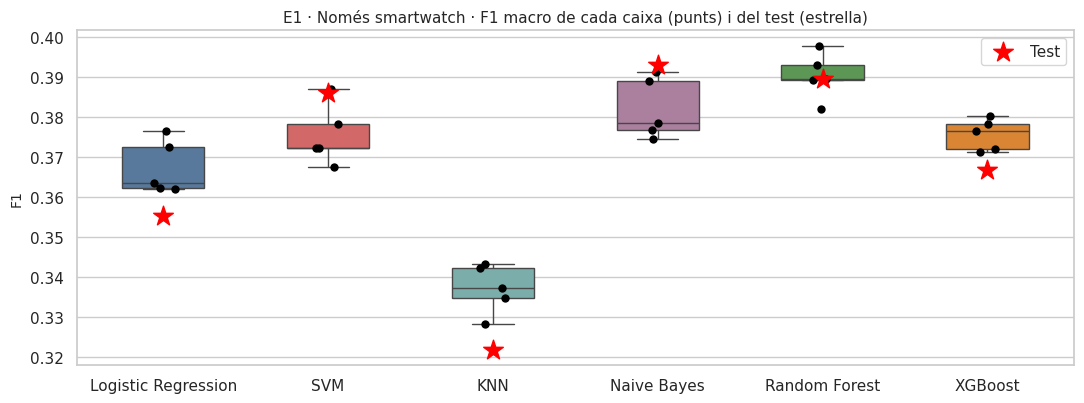

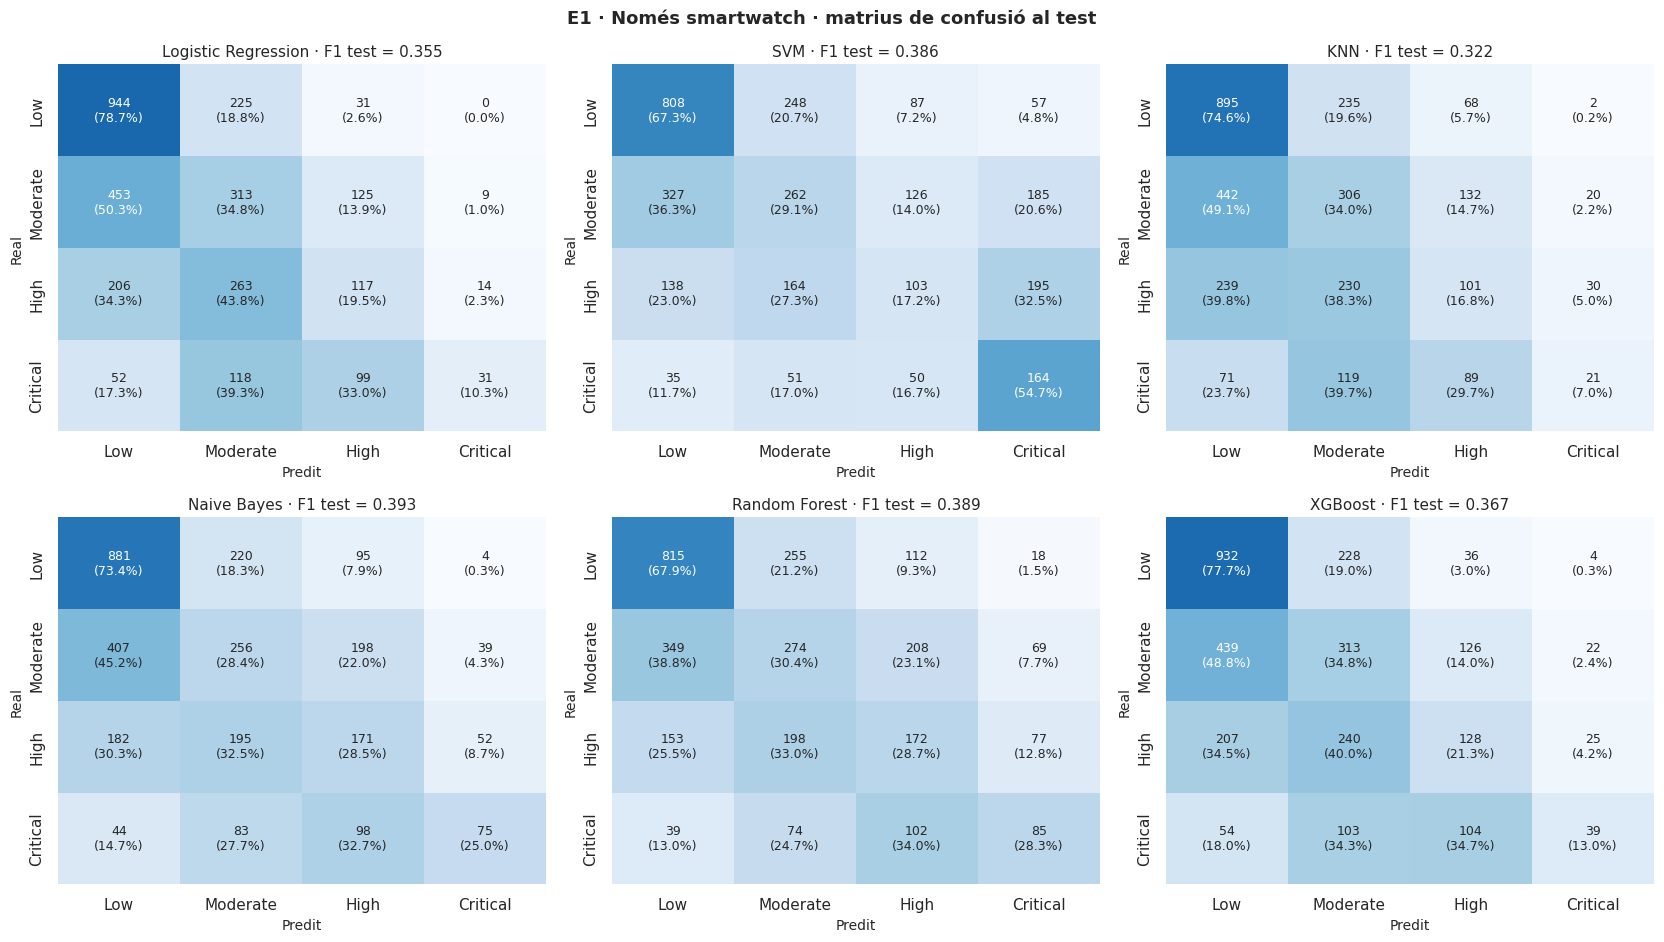

Millor model de E1 (per F1 de la CV): Random Forest · F1 CV = 0.3903 · F1 test = 0.3894 · sensibilitat Critical = 0.283 · sensibilitat High = 0.287


In [9]:
if "E1" in ESCENARIS_ACTIUS:
    RES["E1"] = executar_o_carregar("E1"); mostrar_escenari(RES["E1"], "E1")

### Cel·la 10 · E2 · Consulta sense analítica
**Situació:** visita de control d'infermeria o telefònica, amb una analítica massa antiga per ser útil. Només hi ha la història clínica, la tensió arterial i el tractament. **Pregunta:** fins on arriba el metge sense sang?

E2 · Consulta sense analítica · 11 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 10, 'class_weight': None}
   Caixa 1/5 · F1 = 0.5498 · AUC = 0.8167   (F1 a les caixes d'entrenament = 0.5309)
   Caixa 2/5 · F1 = 0.5403 · AUC = 0.8158   (F1 a les caixes d'entrenament = 0.5318)
   Caixa 3/5 · F1 = 0.5311 · AUC = 0.8128   (F1 a les caixes d'entrenament = 0.5359)
   Caixa 4/5 · F1 = 0.5268 · AUC = 0.8108   (F1 a les caixes d'entrenament = 0.5387)
   Caixa 5/5 · F1 = 0.5282 · AUC = 0.8078   (F1 a les caixes d'entrenament = 0.5372)
   ➜ F1 CV = 0.5352 ± 0.0097 · ESTABLE ✔ · F1 Test = 0.5303 · 3 s

▶ SVM · millors hiperparàmetres: {'C': 10, 'class_weight': 'balanced', 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.5347 · AUC = 0.8137   (F1 a les caixes d'entrenament = 0.5363)
   Caixa 2/5 · F1 = 0.5215 · AUC = 0.8139   (F1 a les caixes d'entrenament = 0.5347)
   Caixa 3/5 · F1 = 0.5181 · AUC = 0.8106   (F1 a les caixes d'entrenament = 0.5358)
   Caixa 4/5 · F1 = 0.5191 · AUC = 0.808

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.5747 ± 0.0083  0.5690  0.5582 ± 0.0089  0.5543      0.5223 ± 0.0105  0.5167  0.5352 ± 0.0097  0.5303  0.8128 ± 0.0036  0.8193  0.8464 ± 0.0031  0.8443  0.6908 ± 0.0051  0.6941
SVM                  0.5423 ± 0.0081  0.5487  0.5157 ± 0.0064  0.5260      0.5371 ± 0.0089  0.5456  0.5232 ± 0.0067  0.5328  0.8105 ± 0.0034  0.8184  0.8426 ± 0.0032  0.8448  0.6853 ± 0.0063  0.6952
KNN                  0.5493 ± 0.0062  0.5560  0.5429 ± 0.0111  0.5593      0.4795 ± 0.0096  0.4876  0.4968 ± 0.0102  0.5072  0.7923 ± 0.0023  0.7992  0.8352 ± 0.0020  0.8373  0.6354 ± 0.0121  0.6433
Naive Bayes          0.5556 ± 0.0050  0.5557  0.5380 ± 0.0083  0.5446      0.5032 ± 0.0059  0.4999  0.5151 ± 0.0055  0.5146  0.7981 ± 0.0022  0.8023  0.8402 ± 0.0016  0.8400  0.6667 ± 0.0042  0.6677
Random Forest        0.5505 ± 0.0102  0.5560  0.5235 ± 0.0129  0.5294      0.5277 ± 0.0106  0.5328  0.5252 ± 0.0115  0.5310  0.8004 ± 0.0027  0.8086  0.8424 ± 0.0033  0.8446  0.6800 ± 0.0036  0.6909
XGBoost              0.5660 ± 0.0062  0.5687  0.5522 ± 0.0089  0.5547      0.5164 ± 0.0026  0.5160  0.5292 ± 0.0032  0.5299  0.8078 ± 0.0028  0.8156  0.8432 ± 0.0021  0.8442  0.6831 ± 0.0039  0.6896


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.5349,0.5352,0.5303,0.0046
SVM,0.5369,0.5232,0.5328,0.0041
KNN,1.0000,0.4968,0.5072,0.4928
Naive Bayes,0.5205,0.5151,0.5146,0.0059
Random Forest,0.8348,0.5252,0.5310,0.3038
XGBoost,0.5793,0.5292,0.5299,0.0494



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.791 ± 0.015  0.784  0.453 ± 0.012  0.461  0.378 ± 0.027  0.348  0.467 ± 0.023  0.473  0.743 ± 0.006  0.741  0.449 ± 0.008  0.449  0.408 ± 0.022  0.382  0.540 ± 0.017  0.549
SVM                        0.675 ± 0.013  0.673  0.397 ± 0.017  0.409  0.455 ± 0.036  0.467  0.622 ± 0.031  0.633  0.712 ± 0.009  0.712  0.409 ± 0.014  0.422  0.418 ± 0.023  0.422  0.554 ± 0.011  0.575
KNN                        0.795 ± 0.010  0.796  0.429 ± 0.013  0.451  0.333 ± 0.020  0.320  0.362 ± 0.033  0.383  0.726 ± 0.004  0.728  0.421 ± 0.009  0.436  0.370 ± 0.020  0.363  0.470 ± 0.034  0.501
Naive Bayes                0.775 ± 0.014  0.762  0.408 ± 0.008  0.431  0.402 ± 0.033  0.410  0.428 ± 0.027  0.397  0.730 ± 0.005  0.723  0.418 ± 0.009  0.432  0.405 ± 0.027  0.414  0.508 ± 0.018  0.490
Random Forest              0.717 ± 0.014  0.712  0.403 ± 0.011  0.438  0.438 ± 0.023  0.418  0.553 ± 0.014  0.563  0.720 ± 0.007  0.722  0.413 ± 0.010  0.438  0.421 ± 0.016  0.410  0.546 ± 0.022  0.554
XGBoost                    0.786 ± 0.017  0.782  0.427 ± 0.007  0.462  0.383 ± 0.021  0.353  0.470 ± 0.027  0.467  0.737 ± 0.008  0.738  0.427 ± 0.004  0.451  0.408 ± 0.013  0.386  0.544 ± 0.016  0.545


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,10,None,—,—,—,—,—,—,—,—,—,—
SVM,10,balanced,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,manhattan,51,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,1e-09,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,12,4,200,—,—
XGBoost,—,—,—,—,—,—,—,3,—,200,0.05,0.8


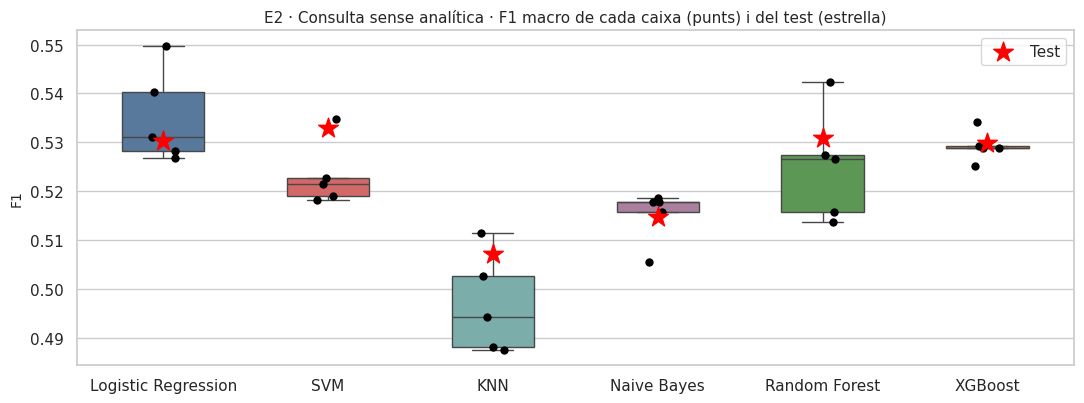

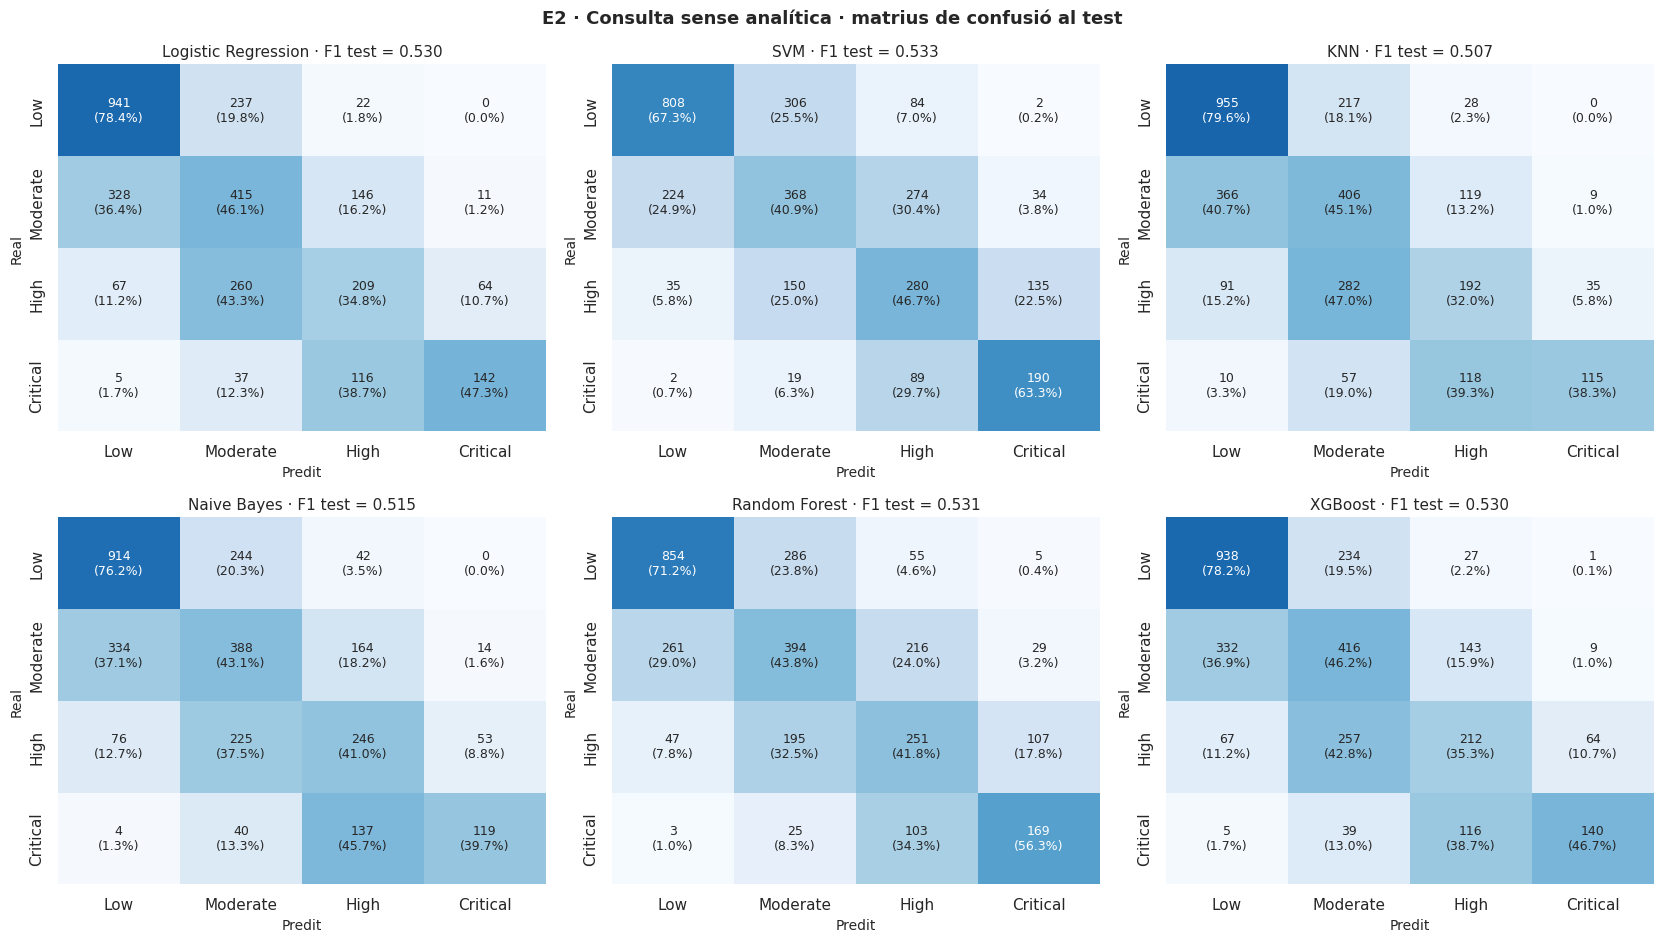

Millor model de E2 (per F1 de la CV): Logistic Regression · F1 CV = 0.5352 · F1 test = 0.5303 · sensibilitat Critical = 0.473 · sensibilitat High = 0.348


In [10]:
if "E2" in ESCENARIS_ACTIUS:
    RES["E2"] = executar_o_carregar("E2"); mostrar_escenari(RES["E2"], "E2")

### Cel·la 11 · E3 · Consulta completa
**Situació:** visita amb analítica recent (HbA1c i glucosa en dejú). És la pràctica habitual actual. **Pregunta:** quant millora el triatge quan hi ha analítica?

E3 · Consulta completa · 13 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 100, 'class_weight': None}
   Caixa 1/5 · F1 = 0.6871 · AUC = 0.9098   (F1 a les caixes d'entrenament = 0.6911)
   Caixa 2/5 · F1 = 0.6916 · AUC = 0.9109   (F1 a les caixes d'entrenament = 0.6909)
   Caixa 3/5 · F1 = 0.6847 · AUC = 0.9036   (F1 a les caixes d'entrenament = 0.6927)
   Caixa 4/5 · F1 = 0.6886 · AUC = 0.9094   (F1 a les caixes d'entrenament = 0.6899)
   Caixa 5/5 · F1 = 0.6961 · AUC = 0.9110   (F1 a les caixes d'entrenament = 0.6892)
   ➜ F1 CV = 0.6896 ± 0.0044 · ESTABLE ✔ · F1 Test = 0.6953 · 4 s

▶ SVM · millors hiperparàmetres: {'C': 1, 'class_weight': None, 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.6799 · AUC = 0.9094   (F1 a les caixes d'entrenament = 0.6931)
   Caixa 2/5 · F1 = 0.6900 · AUC = 0.9102   (F1 a les caixes d'entrenament = 0.6898)
   Caixa 3/5 · F1 = 0.6763 · AUC = 0.9024   (F1 a les caixes d'entrenament = 0.6960)
   Caixa 4/5 · F1 = 0.6849 · AUC = 0.9089   (F1 a les

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.7086 ± 0.0058  0.7157  0.7003 ± 0.0023  0.7044      0.6811 ± 0.0062  0.6879  0.6896 ± 0.0044  0.6953  0.9089 ± 0.0031  0.9121  0.8969 ± 0.0021  0.8999  0.8425 ± 0.0040  0.8473
SVM                  0.7067 ± 0.0095  0.7190  0.7017 ± 0.0050  0.7139      0.6739 ± 0.0102  0.6852  0.6857 ± 0.0083  0.6971  0.9084 ± 0.0035  0.9118  0.8962 ± 0.0034  0.9008  0.8395 ± 0.0064  0.8475
KNN                  0.6826 ± 0.0123  0.6900  0.6879 ± 0.0141  0.6964      0.6332 ± 0.0158  0.6354  0.6531 ± 0.0153  0.6562  0.8935 ± 0.0041  0.8975  0.8866 ± 0.0043  0.8896  0.8156 ± 0.0078  0.8236
Naive Bayes          0.6935 ± 0.0146  0.6960  0.6867 ± 0.0104  0.6889      0.6647 ± 0.0152  0.6662  0.6740 ± 0.0133  0.6755  0.8991 ± 0.0051  0.9012  0.8921 ± 0.0052  0.8933  0.8288 ± 0.0095  0.8301
Random Forest        0.6964 ± 0.0097  0.7030  0.6812 ± 0.0078  0.6914      0.6807 ± 0.0130  0.6915  0.6805 ± 0.0103  0.6907  0.9013 ± 0.0052  0.9051  0.8943 ± 0.0034  0.8969  0.8351 ± 0.0066  0.8433
XGBoost              0.7007 ± 0.0127  0.7100  0.6912 ± 0.0082  0.6994      0.6726 ± 0.0132  0.6790  0.6809 ± 0.0112  0.6878  0.9036 ± 0.0039  0.9077  0.8943 ± 0.0045  0.8980  0.8364 ± 0.0067  0.8419


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.6908,0.6896,0.6953,-0.0045
SVM,0.6925,0.6857,0.6971,-0.0045
KNN,1.0000,0.6531,0.6562,0.3438
Naive Bayes,0.6757,0.6740,0.6755,0.0002
Random Forest,0.8802,0.6805,0.6907,0.1895
XGBoost,0.7518,0.6809,0.6878,0.0639



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.842 ± 0.010  0.840  0.628 ± 0.020  0.633  0.578 ± 0.015  0.618  0.676 ± 0.018  0.660  0.837 ± 0.005  0.840  0.613 ± 0.013  0.625  0.589 ± 0.006  0.612  0.719 ± 0.009  0.705
SVM                        0.840 ± 0.011  0.841  0.639 ± 0.020  0.650  0.575 ± 0.015  0.627  0.642 ± 0.020  0.623  0.837 ± 0.007  0.842  0.616 ± 0.016  0.633  0.585 ± 0.012  0.618  0.705 ± 0.007  0.695
KNN                        0.835 ± 0.012  0.840  0.637 ± 0.013  0.643  0.516 ± 0.032  0.552  0.546 ± 0.028  0.507  0.824 ± 0.009  0.833  0.596 ± 0.016  0.605  0.541 ± 0.030  0.561  0.651 ± 0.023  0.626
Naive Bayes                0.812 ± 0.017  0.800  0.636 ± 0.028  0.640  0.569 ± 0.007  0.615  0.642 ± 0.033  0.610  0.823 ± 0.013  0.819  0.606 ± 0.023  0.612  0.575 ± 0.006  0.602  0.692 ± 0.018  0.669
Random Forest              0.804 ± 0.009  0.792  0.622 ± 0.017  0.623  0.584 ± 0.014  0.640  0.713 ± 0.032  0.710  0.826 ± 0.007  0.823  0.604 ± 0.015  0.609  0.580 ± 0.014  0.612  0.712 ± 0.017  0.718
XGBoost                    0.833 ± 0.015  0.830  0.625 ± 0.020  0.641  0.567 ± 0.012  0.612  0.665 ± 0.024  0.633  0.832 ± 0.009  0.836  0.606 ± 0.018  0.622  0.579 ± 0.016  0.607  0.706 ± 0.017  0.686


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,100,None,—,—,—,—,—,—,—,—,—,—
SVM,1,None,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,euclidean,51,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,0.0001,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,12,4,200,—,—
XGBoost,—,—,—,—,—,—,—,3,—,200,0.1,0.8


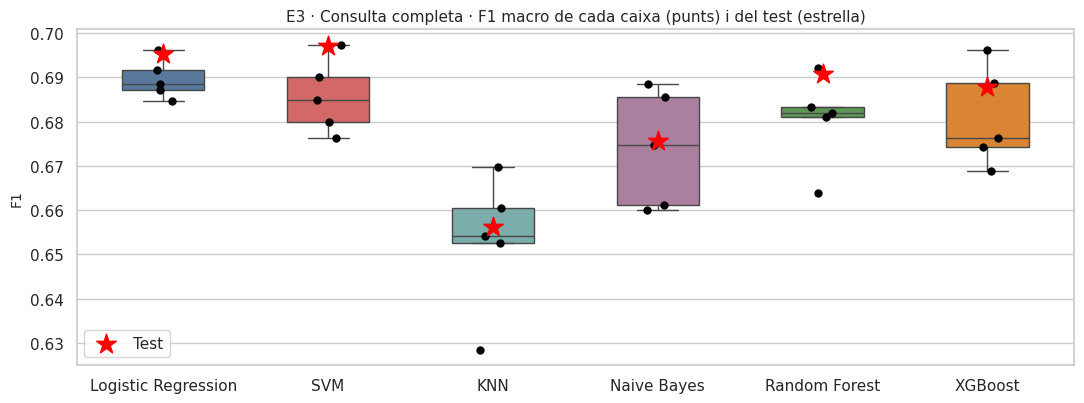

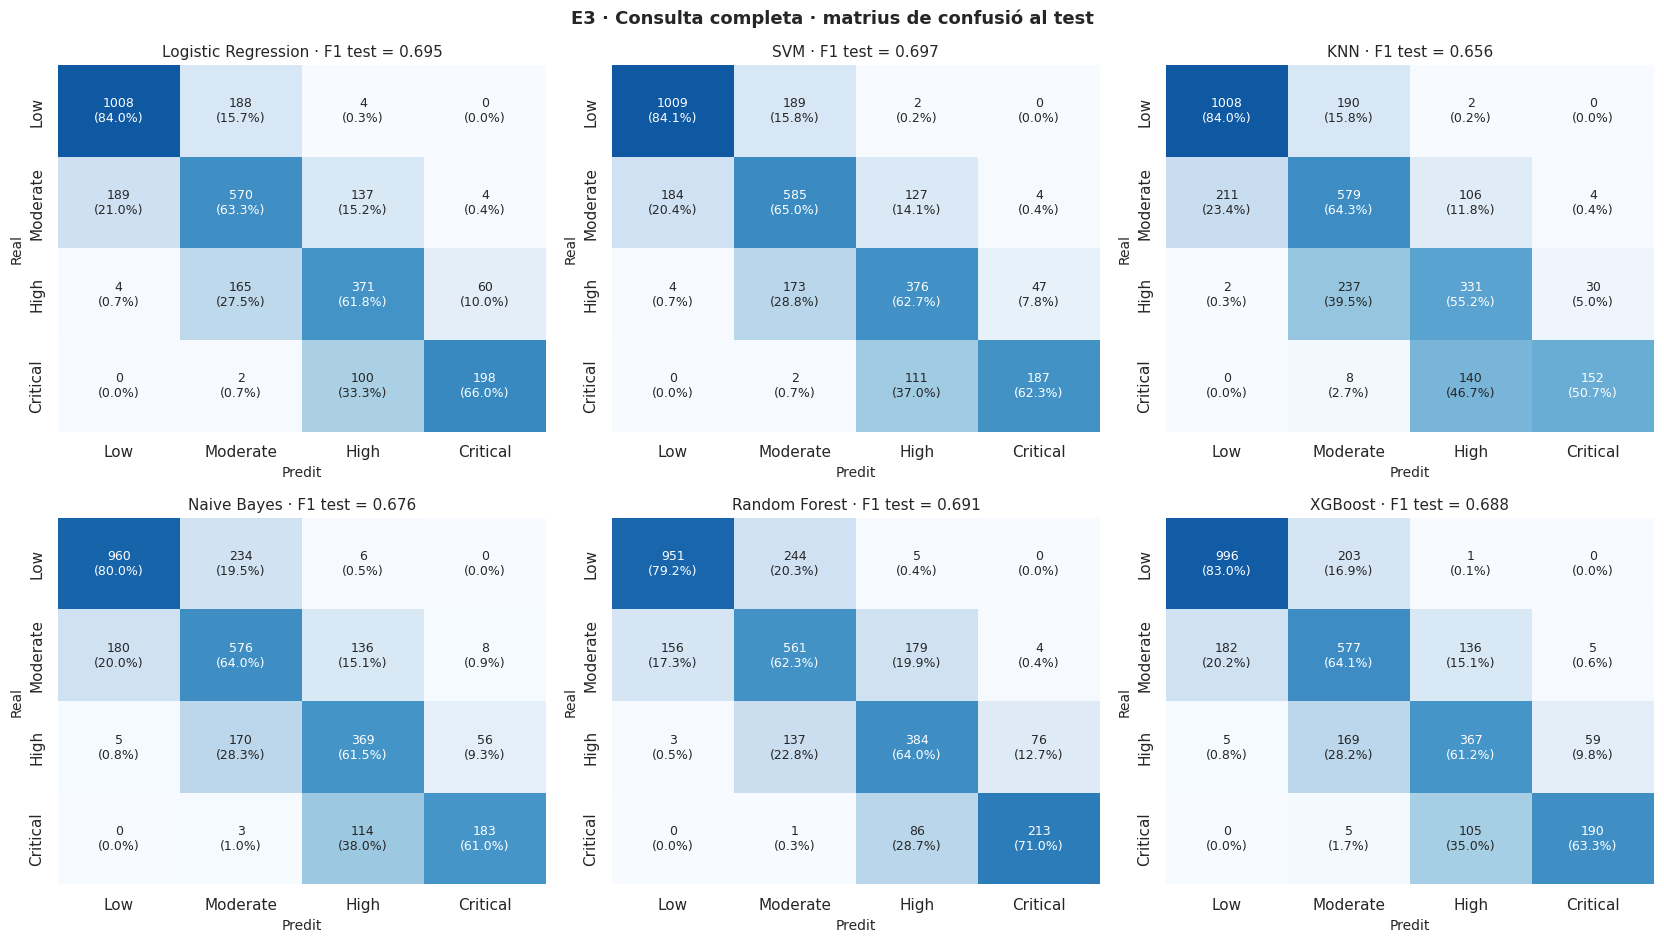

Millor model de E3 (per F1 de la CV): Logistic Regression · F1 CV = 0.6896 · F1 test = 0.6953 · sensibilitat Critical = 0.660 · sensibilitat High = 0.618


In [11]:
if "E3" in ESCENARIS_ACTIUS:
    RES["E3"] = executar_o_carregar("E3"); mostrar_escenari(RES["E3"], "E3")

### Cel·la 12 · E4 · Història clínica + smartwatch
**Situació:** telemonitoratge entre visites per a pacients sense CGM (la majoria de pacients amb diabetis tipus 2). **Pregunta central del TFG:** el rellotge aporta informació nova a la que ja té el metge?

E4 · Història clínica + smartwatch · 22 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 10, 'class_weight': None}
   Caixa 1/5 · F1 = 0.6143 · AUC = 0.8657   (F1 a les caixes d'entrenament = 0.6113)
   Caixa 2/5 · F1 = 0.5937 · AUC = 0.8641   (F1 a les caixes d'entrenament = 0.6165)
   Caixa 3/5 · F1 = 0.6176 · AUC = 0.8708   (F1 a les caixes d'entrenament = 0.6136)
   Caixa 4/5 · F1 = 0.6079 · AUC = 0.8643   (F1 a les caixes d'entrenament = 0.6164)
   Caixa 5/5 · F1 = 0.6069 · AUC = 0.8581   (F1 a les caixes d'entrenament = 0.6170)
   ➜ F1 CV = 0.6081 ± 0.0092 · ESTABLE ✔ · F1 Test = 0.6177 · 5 s

▶ SVM · millors hiperparàmetres: {'C': 1, 'class_weight': None, 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.6097 · AUC = 0.8643   (F1 a les caixes d'entrenament = 0.6248)
   Caixa 2/5 · F1 = 0.5915 · AUC = 0.8608   (F1 a les caixes d'entrenament = 0.6251)
   Caixa 3/5 · F1 = 0.6191 · AUC = 0.8682   (F1 a les caixes d'entrenament = 0.6214)
   Caixa 4/5 · F1 = 0.6024 · AUC = 0.8632 

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.6365 ± 0.0050  0.6423  0.6249 ± 0.0078  0.6375      0.5963 ± 0.0108  0.6039  0.6081 ± 0.0092  0.6177  0.8646 ± 0.0045  0.8648  0.8706 ± 0.0015  0.8722  0.7787 ± 0.0079  0.7798
SVM                  0.6372 ± 0.0059  0.6390  0.6381 ± 0.0099  0.6399      0.5869 ± 0.0116  0.5862  0.6051 ± 0.0102  0.6053  0.8629 ± 0.0038  0.8642  0.8704 ± 0.0021  0.8710  0.7732 ± 0.0081  0.7733
KNN                  0.5751 ± 0.0080  0.5700  0.5753 ± 0.0133  0.5728      0.5011 ± 0.0125  0.4961  0.5200 ± 0.0133  0.5158  0.8140 ± 0.0055  0.8178  0.8452 ± 0.0029  0.8432  0.6803 ± 0.0171  0.6807
Naive Bayes          0.5860 ± 0.0080  0.5870  0.5756 ± 0.0108  0.5855      0.5451 ± 0.0051  0.5474  0.5558 ± 0.0062  0.5614  0.8244 ± 0.0020  0.8268  0.8534 ± 0.0030  0.8527  0.7143 ± 0.0065  0.7206
Random Forest        0.6146 ± 0.0031  0.6140  0.5924 ± 0.0060  0.5980      0.5814 ± 0.0081  0.5837  0.5862 ± 0.0057  0.5902  0.8461 ± 0.0022  0.8479  0.8644 ± 0.0014  0.8637  0.7590 ± 0.0058  0.7659
XGBoost              0.6231 ± 0.0094  0.6303  0.6056 ± 0.0167  0.6197      0.5789 ± 0.0156  0.5887  0.5898 ± 0.0159  0.6015  0.8554 ± 0.0028  0.8576  0.8660 ± 0.0030  0.8683  0.7620 ± 0.0109  0.7674


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.6150,0.6081,0.6177,-0.0028
SVM,0.6239,0.6051,0.6053,0.0187
KNN,1.0000,0.5200,0.5158,0.4842
Naive Bayes,0.5604,0.5558,0.5614,-0.0010
Random Forest,0.9652,0.5862,0.5902,0.3750
XGBoost,0.7178,0.5898,0.6015,0.1162



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.815 ± 0.012  0.817  0.528 ± 0.009  0.536  0.480 ± 0.023  0.487  0.562 ± 0.034  0.577  0.795 ± 0.005  0.795  0.518 ± 0.007  0.524  0.495 ± 0.021  0.503  0.625 ± 0.027  0.649
SVM                        0.813 ± 0.008  0.812  0.548 ± 0.006  0.566  0.489 ± 0.016  0.477  0.497 ± 0.040  0.490  0.796 ± 0.003  0.797  0.526 ± 0.005  0.536  0.500 ± 0.013  0.493  0.599 ± 0.031  0.595
KNN                        0.826 ± 0.011  0.822  0.444 ± 0.014  0.444  0.380 ± 0.032  0.362  0.354 ± 0.038  0.357  0.757 ± 0.006  0.753  0.440 ± 0.008  0.437  0.407 ± 0.024  0.392  0.476 ± 0.041  0.481
Naive Bayes                0.772 ± 0.021  0.767  0.436 ± 0.008  0.449  0.492 ± 0.016  0.480  0.481 ± 0.021  0.493  0.756 ± 0.015  0.750  0.449 ± 0.010  0.451  0.461 ± 0.016  0.463  0.558 ± 0.025  0.582
Random Forest              0.783 ± 0.010  0.784  0.498 ± 0.006  0.492  0.476 ± 0.020  0.468  0.569 ± 0.029  0.590  0.779 ± 0.004  0.778  0.495 ± 0.006  0.488  0.473 ± 0.014  0.468  0.598 ± 0.016  0.627
XGBoost                    0.810 ± 0.012  0.813  0.514 ± 0.007  0.530  0.457 ± 0.023  0.448  0.534 ± 0.046  0.563  0.788 ± 0.005  0.793  0.505 ± 0.004  0.518  0.471 ± 0.020  0.464  0.594 ± 0.045  0.632


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,10,None,—,—,—,—,—,—,—,—,—,—
SVM,1,None,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,euclidean,21,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,1e-09,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,None,4,400,—,—
XGBoost,—,—,—,—,—,—,—,3,—,400,0.05,0.8


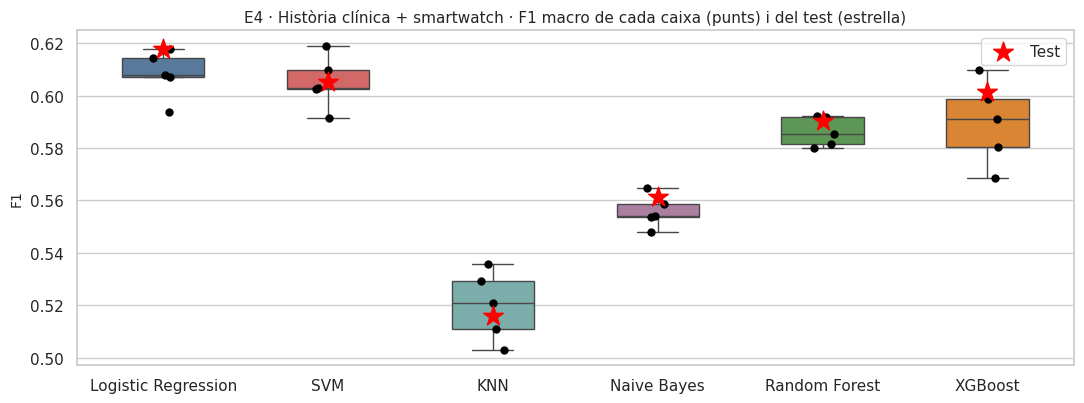

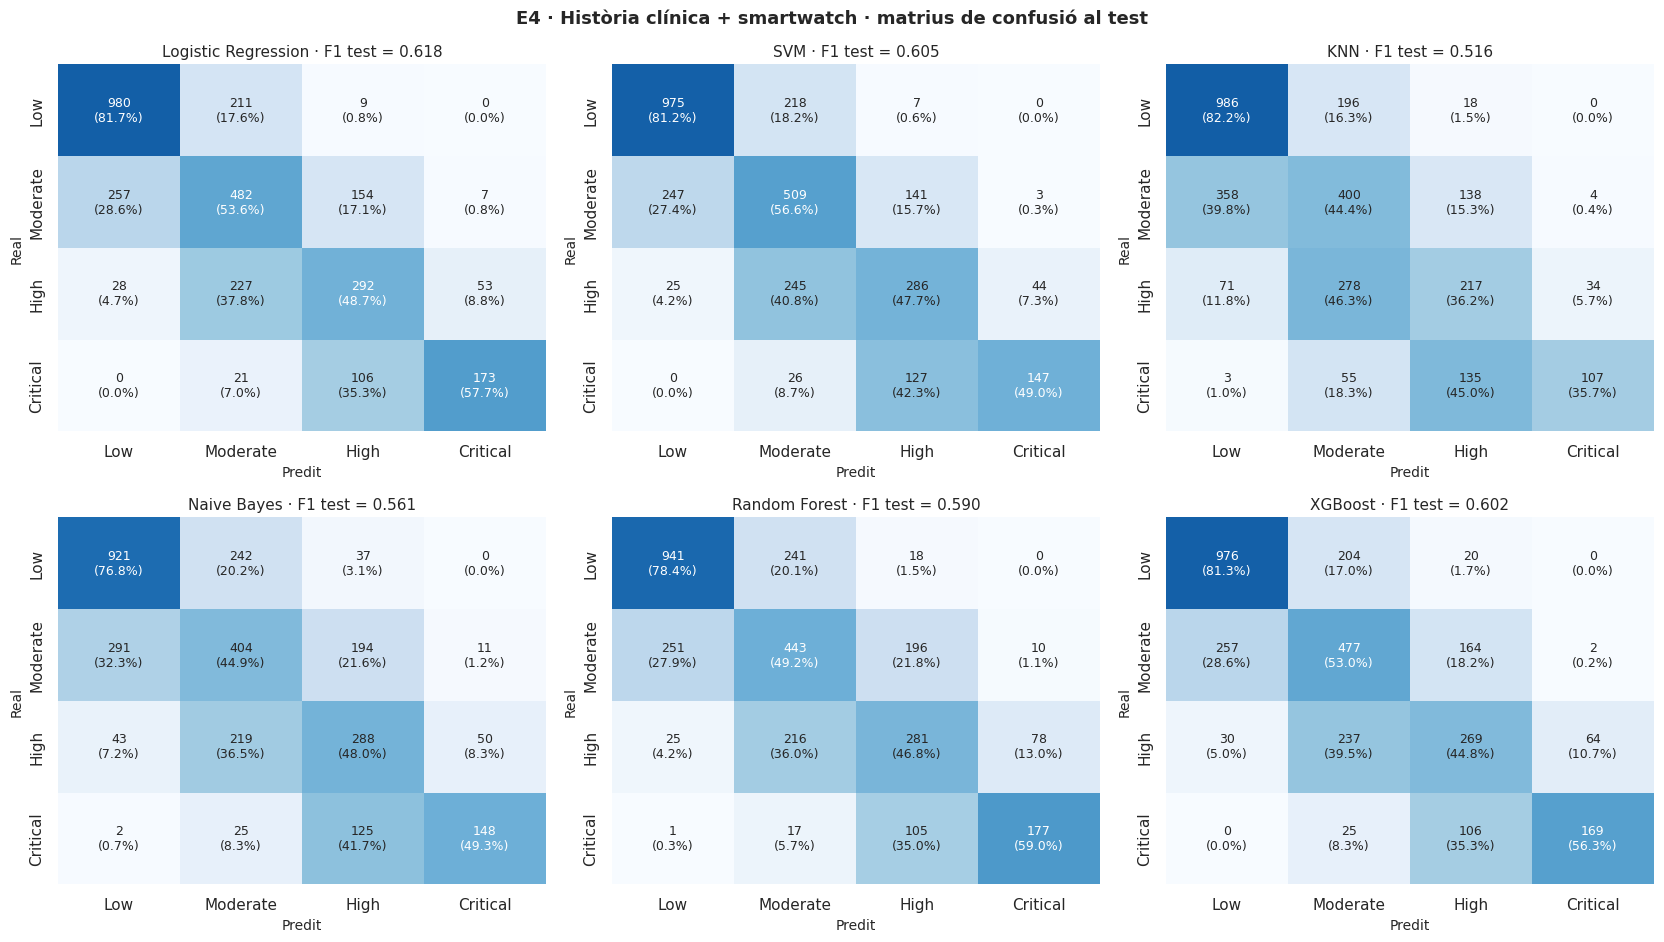

Millor model de E4 (per F1 de la CV): Logistic Regression · F1 CV = 0.6081 · F1 test = 0.6177 · sensibilitat Critical = 0.577 · sensibilitat High = 0.487


In [12]:
if "E4" in ESCENARIS_ACTIUS:
    RES["E4"] = executar_o_carregar("E4"); mostrar_escenari(RES["E4"], "E4")

### Cel·la 13 · E5 · Història clínica + smartwatch + CGM
**Situació:** telemonitoratge per a pacients amb CGM finançat (tipus 1 i tipus 2 amb insulina intensiva). **Pregunta:** quant aporta el sensor de glucosa?

E5 · Història clínica + smartwatch + CGM · 25 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 0.1, 'class_weight': None}
   Caixa 1/5 · F1 = 0.6839 · AUC = 0.9011   (F1 a les caixes d'entrenament = 0.6853)
   Caixa 2/5 · F1 = 0.6672 · AUC = 0.8983   (F1 a les caixes d'entrenament = 0.6900)
   Caixa 3/5 · F1 = 0.6779 · AUC = 0.9045   (F1 a les caixes d'entrenament = 0.6869)
   Caixa 4/5 · F1 = 0.6872 · AUC = 0.9075   (F1 a les caixes d'entrenament = 0.6844)
   Caixa 5/5 · F1 = 0.6822 · AUC = 0.9027   (F1 a les caixes d'entrenament = 0.6855)
   ➜ F1 CV = 0.6797 ± 0.0077 · ESTABLE ✔ · F1 Test = 0.6877 · 5 s

▶ SVM · millors hiperparàmetres: {'C': 1, 'class_weight': None, 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.6747 · AUC = 0.8999   (F1 a les caixes d'entrenament = 0.6961)
   Caixa 2/5 · F1 = 0.6545 · AUC = 0.8960   (F1 a les caixes d'entrenament = 0.7027)
   Caixa 3/5 · F1 = 0.6768 · AUC = 0.9023   (F1 a les caixes d'entrenament = 0.6961)
   Caixa 4/5 · F1 = 0.6751 · AUC = 

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.7009 ± 0.0054  0.7030  0.6940 ± 0.0048  0.7030      0.6688 ± 0.0103  0.6758  0.6797 ± 0.0077  0.6877  0.9028 ± 0.0035  0.9056  0.8940 ± 0.0020  0.8945  0.8331 ± 0.0043  0.8353
SVM                  0.6953 ± 0.0060  0.7030  0.6945 ± 0.0107  0.7128      0.6568 ± 0.0107  0.6745  0.6717 ± 0.0097  0.6902  0.9011 ± 0.0036  0.9053  0.8920 ± 0.0020  0.8945  0.8275 ± 0.0058  0.8342
KNN                  0.6202 ± 0.0076  0.6277  0.6354 ± 0.0141  0.6504      0.5451 ± 0.0089  0.5547  0.5685 ± 0.0097  0.5800  0.8527 ± 0.0052  0.8626  0.8617 ± 0.0026  0.8644  0.7417 ± 0.0083  0.7521
Naive Bayes          0.6249 ± 0.0096  0.6283  0.6208 ± 0.0063  0.6392      0.5876 ± 0.0056  0.5944  0.6002 ± 0.0051  0.6112  0.8542 ± 0.0047  0.8582  0.8673 ± 0.0036  0.8678  0.7607 ± 0.0082  0.7667
Random Forest        0.6613 ± 0.0080  0.6657  0.6437 ± 0.0078  0.6555      0.6348 ± 0.0097  0.6455  0.6387 ± 0.0085  0.6501  0.8758 ± 0.0045  0.8798  0.8815 ± 0.0027  0.8829  0.8020 ± 0.0086  0.8132
XGBoost              0.6788 ± 0.0066  0.6903  0.6652 ± 0.0100  0.6836      0.6432 ± 0.0093  0.6597  0.6527 ± 0.0087  0.6702  0.8920 ± 0.0032  0.8967  0.8865 ± 0.0022  0.8905  0.8167 ± 0.0046  0.8243


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.6864,0.6797,0.6877,-0.0013
SVM,0.6980,0.6717,0.6902,0.0078
KNN,1.0000,0.5685,0.5800,0.4200
Naive Bayes,0.6058,0.6002,0.6112,-0.0054
Random Forest,0.9509,0.6387,0.6501,0.3009
XGBoost,0.8368,0.6527,0.6702,0.1666



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.844 ± 0.009  0.837  0.616 ± 0.014  0.623  0.569 ± 0.025  0.570  0.646 ± 0.030  0.673  0.834 ± 0.003  0.831  0.603 ± 0.009  0.605  0.579 ± 0.020  0.581  0.703 ± 0.023  0.735
SVM                        0.834 ± 0.011  0.824  0.626 ± 0.009  0.642  0.575 ± 0.021  0.575  0.593 ± 0.030  0.657  0.830 ± 0.006  0.829  0.602 ± 0.006  0.608  0.578 ± 0.019  0.584  0.677 ± 0.027  0.739
KNN                        0.857 ± 0.012  0.866  0.514 ± 0.012  0.524  0.423 ± 0.022  0.412  0.387 ± 0.026  0.417  0.793 ± 0.005  0.800  0.500 ± 0.013  0.512  0.455 ± 0.021  0.442  0.526 ± 0.032  0.566
Naive Bayes                0.787 ± 0.022  0.787  0.508 ± 0.017  0.511  0.521 ± 0.008  0.523  0.534 ± 0.019  0.557  0.781 ± 0.015  0.780  0.507 ± 0.017  0.504  0.498 ± 0.012  0.505  0.615 ± 0.011  0.656
Random Forest              0.804 ± 0.015  0.802  0.560 ± 0.021  0.561  0.543 ± 0.013  0.545  0.633 ± 0.026  0.673  0.810 ± 0.008  0.813  0.555 ± 0.016  0.552  0.532 ± 0.008  0.534  0.658 ± 0.020  0.701
XGBoost                    0.832 ± 0.011  0.829  0.592 ± 0.010  0.614  0.536 ± 0.013  0.548  0.613 ± 0.031  0.647  0.824 ± 0.009  0.827  0.579 ± 0.004  0.595  0.545 ± 0.011  0.558  0.664 ± 0.023  0.702


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,0.1,None,—,—,—,—,—,—,—,—,—,—
SVM,1,None,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,euclidean,31,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,1e-09,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,12,4,200,—,—
XGBoost,—,—,—,—,—,—,—,3,—,400,0.1,0.8


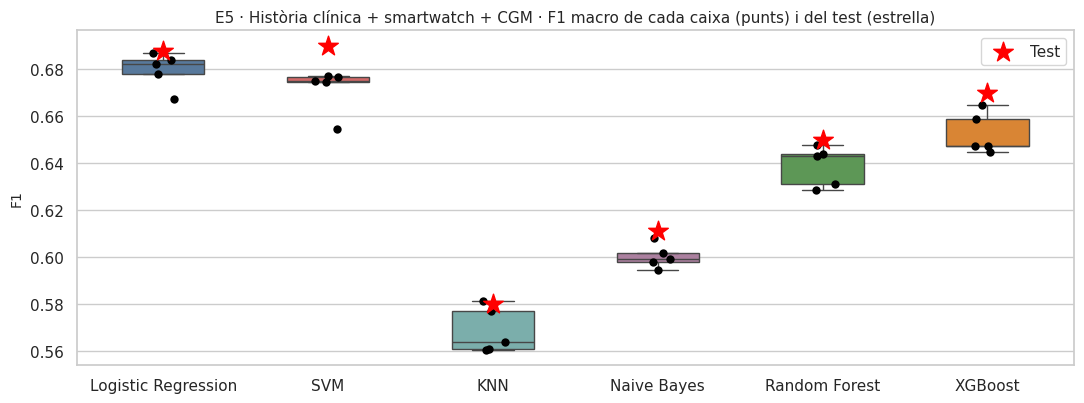

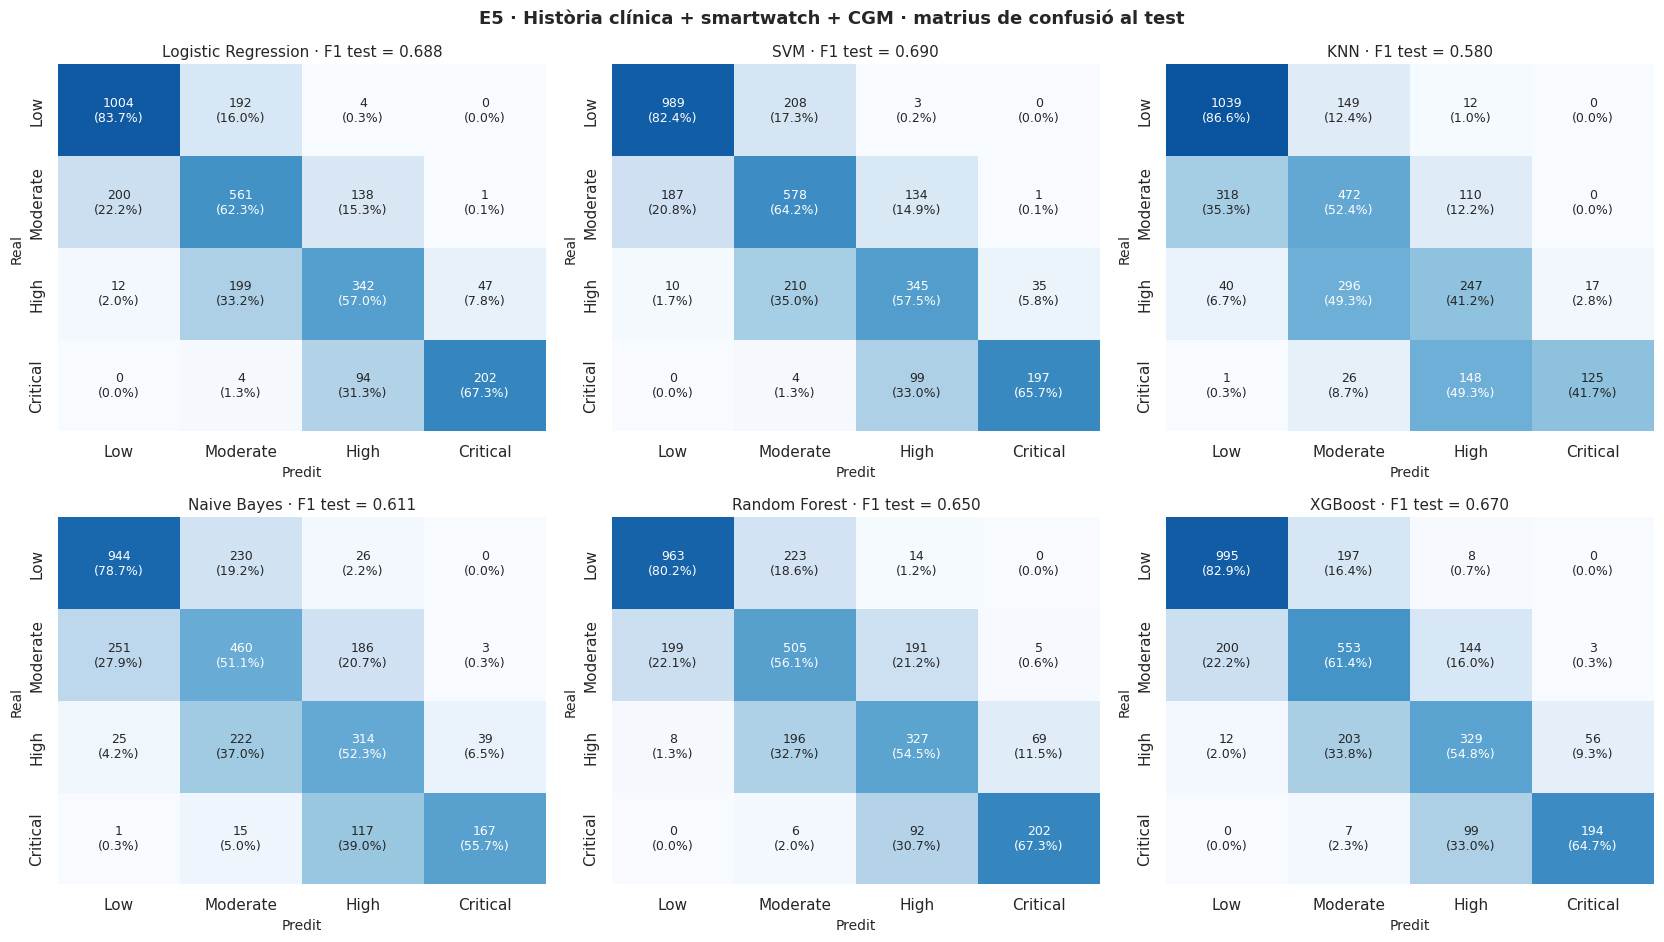

Millor model de E5 (per F1 de la CV): Logistic Regression · F1 CV = 0.6797 · F1 test = 0.6877 · sensibilitat Critical = 0.673 · sensibilitat High = 0.570


In [13]:
if "E5" in ESCENARIS_ACTIUS:
    RES["E5"] = executar_o_carregar("E5"); mostrar_escenari(RES["E5"], "E5")

### Cel·la 14 · E6 · Tot (control de reproductibilitat)
Les 32 variables. Ha de donar **els mateixos resultats que l'Escenari A de la Llibreta 3** (per exemple, Logistic Regression amb F1 CV = 0,9916 ± 0,0013 i F1 test = 0,9909). Si coincideix, queda demostrat que tots els escenaris de la Llibreta 4 són comparables amb la Llibreta 3.

E6 · Tot · 32 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 100, 'class_weight': 'balanced'}
   Caixa 1/5 · F1 = 0.9917 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9976)
   Caixa 2/5 · F1 = 0.9897 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9962)
   Caixa 3/5 · F1 = 0.9933 · AUC = 1.0000   (F1 a les caixes d'entrenament = 0.9959)
   Caixa 4/5 · F1 = 0.9920 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9969)
   Caixa 5/5 · F1 = 0.9911 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9965)
   ➜ F1 CV = 0.9916 ± 0.0013 · ESTABLE ✔ · F1 Test = 0.9909 · 8 s

▶ SVM · millors hiperparàmetres: {'C': 10, 'class_weight': None, 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.9662 · AUC = 0.9989   (F1 a les caixes d'entrenament = 0.9952)
   Caixa 2/5 · F1 = 0.9531 · AUC = 0.9984   (F1 a les caixes d'entrenament = 0.9956)
   Caixa 3/5 · F1 = 0.9560 · AUC = 0.9984   (F1 a les caixes d'entrenament = 0.9953)
   Caixa 4/5 · F1 = 0.9712 · AUC = 0.9988   (F1 a les caixes

Accuracy                Precision         Recall (Sensitivity)                 F1-score                      AUC              Specificity           Kappa ponderat        
                            Training    Test         Training    Test             Training    Test         Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.9923 ± 0.0011  0.9927  0.9905 ± 0.0018  0.9895      0.9927 ± 0.0009  0.9924  0.9916 ± 0.0013  0.9909  0.9999 ± 0.0000  0.9999  0.9974 ± 0.0004  0.9976  0.9962 ± 0.0005  0.9963
SVM                  0.9675 ± 0.0073  0.9723  0.9651 ± 0.0077  0.9698      0.9616 ± 0.0087  0.9688  0.9633 ± 0.0082  0.9693  0.9987 ± 0.0003  0.9991  0.9887 ± 0.0025  0.9905  0.9837 ± 0.0037  0.9861
KNN                  0.7566 ± 0.0078  0.7677  0.7776 ± 0.0111  0.7802      0.6956 ± 0.0142  0.7013  0.7217 ± 0.0148  0.7262  0.9347 ± 0.0021  0.9397  0.9127 ± 0.0024  0.9170  0.8644 ± 0.0059  0.8737
Naive Bayes          0.7706 ± 0.0097  0.7740  0.7687 ± 0.0072  0.7648      0.7462 ± 0.0123  0.7477  0.7550 ± 0.0103  0.7548  0.9393 ± 0.0041  0.9389  0.9200 ± 0.0034  0.9215  0.8780 ± 0.0063  0.8820
Random Forest        0.8250 ± 0.0069  0.8223  0.8186 ± 0.0085  0.8096      0.8053 ± 0.0085  0.7984  0.8112 ± 0.0082  0.8034  0.9604 ± 0.0030  0.9619  0.9389 ± 0.0022  0.9382  0.9101 ± 0.0039  0.9088
XGBoost              0.9078 ± 0.0081  0.9130  0.9063 ± 0.0096  0.9076      0.8862 ± 0.0095  0.8942  0.8950 ± 0.0096  0.9001  0.9885 ± 0.0008  0.9906  0.9679 ± 0.0028  0.9699  0.9526 ± 0.0041  0.9555


SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.9966,0.9916,0.9909,0.0057
SVM,0.9952,0.9633,0.9693,0.0260
KNN,1.0000,0.7217,0.7262,0.2738
Naive Bayes,0.7605,0.7550,0.7548,0.0057
Random Forest,0.9947,0.8112,0.8034,0.1913
XGBoost,1.0000,0.8950,0.9001,0.0999



SENSIBILITAT I F1 PER CLASSE


Recall (Sensitivity)                                                                                F1-score                                                                         
                                     Low              Moderate                  High              Critical                   Low              Moderate                  High              Critical       
                                Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test       Training   Test
Logistic Regression        0.996 ± 0.003  0.997  0.989 ± 0.005  0.991  0.988 ± 0.003  0.985  0.998 ± 0.002  0.997  0.997 ± 0.002  0.997  0.990 ± 0.002  0.992  0.988 ± 0.003  0.987  0.992 ± 0.003  0.987
SVM                        0.985 ± 0.006  0.986  0.961 ± 0.010  0.971  0.951 ± 0.011  0.948  0.949 ± 0.021  0.970  0.985 ± 0.004  0.989  0.959 ± 0.009  0.964  0.949 ± 0.011  0.953  0.960 ± 0.011  0.972
KNN                        0.900 ± 0.008  0.919  0.747 ± 0.012  0.751  0.590 ± 0.033  0.612  0.546 ± 0.048  0.523  0.880 ± 0.004  0.892  0.696 ± 0.006  0.714  0.619 ± 0.028  0.630  0.691 ± 0.042  0.668
Naive Bayes                0.837 ± 0.010  0.854  0.759 ± 0.019  0.750  0.693 ± 0.009  0.687  0.697 ± 0.036  0.700  0.868 ± 0.007  0.878  0.711 ± 0.015  0.715  0.686 ± 0.015  0.677  0.755 ± 0.023  0.749
Random Forest              0.898 ± 0.008  0.896  0.796 ± 0.017  0.794  0.743 ± 0.011  0.753  0.784 ± 0.014  0.750  0.909 ± 0.003  0.905  0.772 ± 0.011  0.778  0.744 ± 0.017  0.746  0.820 ± 0.014  0.785
XGBoost                    0.953 ± 0.004  0.947  0.910 ± 0.020  0.920  0.855 ± 0.014  0.873  0.827 ± 0.029  0.837  0.958 ± 0.004  0.957  0.886 ± 0.013  0.896  0.853 ± 0.013  0.868  0.882 ± 0.023  0.879


MILLORS HIPERPARÀMETRES


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,100,balanced,—,—,—,—,—,—,—,—,—,—
SVM,10,None,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,euclidean,21,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,0.001,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,None,4,200,—,—
XGBoost,—,—,—,—,—,—,—,5,—,400,0.1,0.8


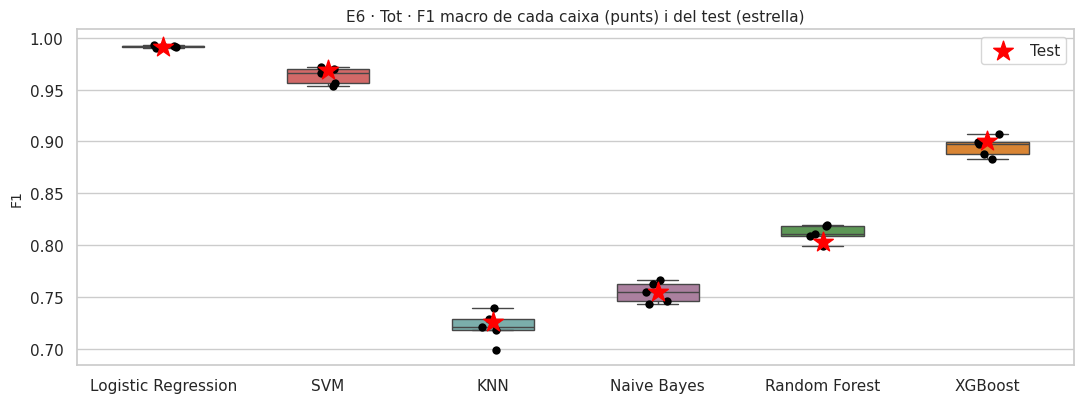

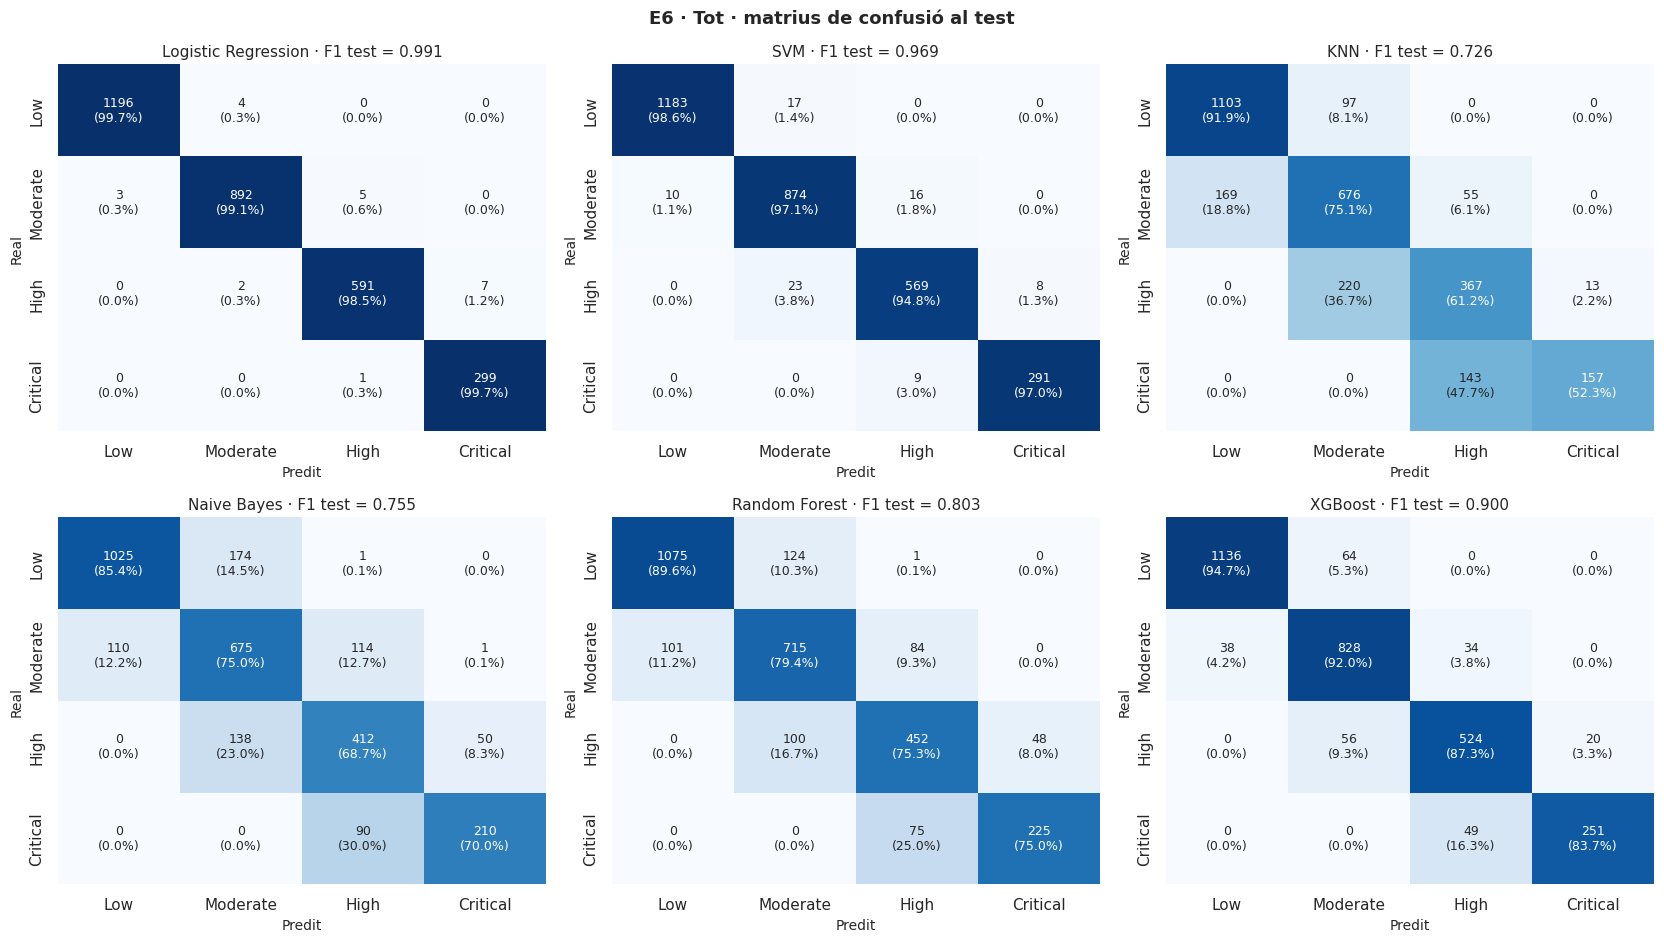

Millor model de E6 (per F1 de la CV): Logistic Regression · F1 CV = 0.9916 · F1 test = 0.9909 · sensibilitat Critical = 0.997 · sensibilitat High = 0.985

Control de reproductibilitat · LR a E6: F1 test = 0.9909 (Llibreta 3, Escenari A: 0.9909) -> COINCIDEIX ✔


In [14]:
if "E6" in ESCENARIS_ACTIUS:
    RES["E6"] = executar_o_carregar("E6"); mostrar_escenari(RES["E6"], "E6")
    if "Logistic Regression" in RES["E6"] and not MODE_RAPID:
        f1 = RES["E6"]["Logistic Regression"]["test"]["F1-score"]
        print(f"\nControl de reproductibilitat · LR a E6: F1 test = {f1:.4f} (Llibreta 3, Escenari A: 0.9909) ->",
              "COINCIDEIX ✔" if abs(f1 - 0.9909) < 0.0005 else "NO COINCIDEIX ✘ (revisar versió de les llibreries o les dades)")

## BLOC 4 · Comparativa entre escenaris
### Cel·la 15 · Taula i gràfics comparatius
- **Mapes de calor (models × escenaris):** F1 macro al test i sensibilitat de Critical i de High. Com més verd, millor.
- **Gràfic de línies:** F1 de cada model d'E1 a E6 (punts = test; barres = mitjana ± SD de la validació creuada). Permet veure quins models aprofiten millor cada font de dades i si el millor model canvia segons l'escenari.
- **Millor model de cada escenari** (triat per l'F1 de la validació creuada, no pel test).

F1 MACRO AL TEST (models × escenaris)


,E1,E2,E3,E4,E5,E6
Logistic Regression,0.3553,0.5303,0.6953,0.6177,0.6877,0.9909
SVM,0.3860,0.5328,0.6971,0.6053,0.6902,0.9693
KNN,0.3218,0.5072,0.6562,0.5158,0.5800,0.7262
Naive Bayes,0.3931,0.5146,0.6755,0.5614,0.6112,0.7548
Random Forest,0.3894,0.5310,0.6907,0.5902,0.6501,0.8034
XGBoost,0.3667,0.5299,0.6878,0.6015,0.6702,0.9001


F1 MACRO A LA VALIDACIÓ CREUADA (mitjana)


,E1,E2,E3,E4,E5,E6
Logistic Regression,0.3673,0.5352,0.6896,0.6081,0.6797,0.9916
SVM,0.3755,0.5232,0.6857,0.6051,0.6717,0.9633
KNN,0.3371,0.4968,0.6531,0.5200,0.5685,0.7217
Naive Bayes,0.3820,0.5151,0.6740,0.5558,0.6002,0.7550
Random Forest,0.3903,0.5252,0.6805,0.5862,0.6387,0.8112
XGBoost,0.3757,0.5292,0.6809,0.5898,0.6527,0.8950


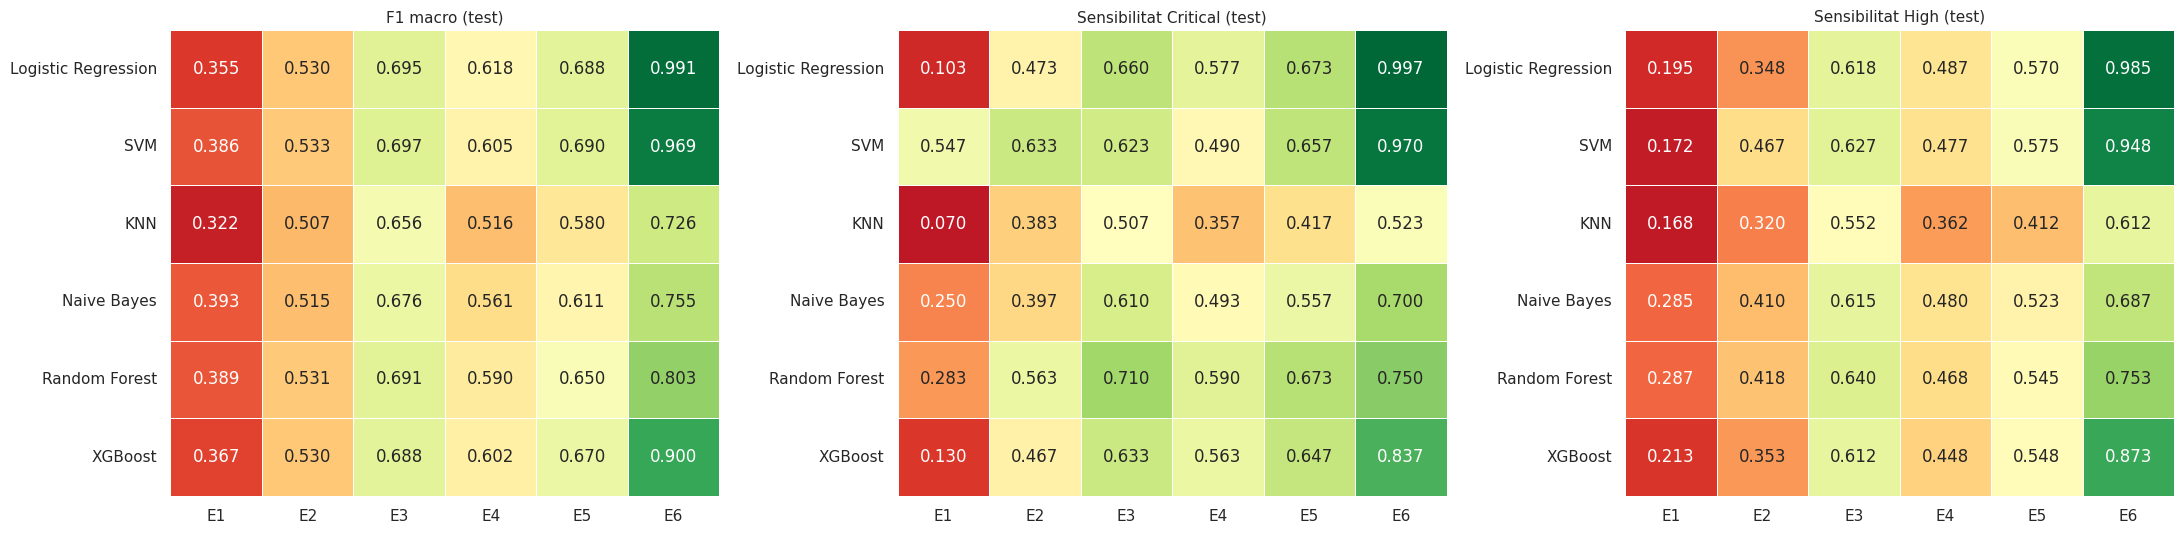

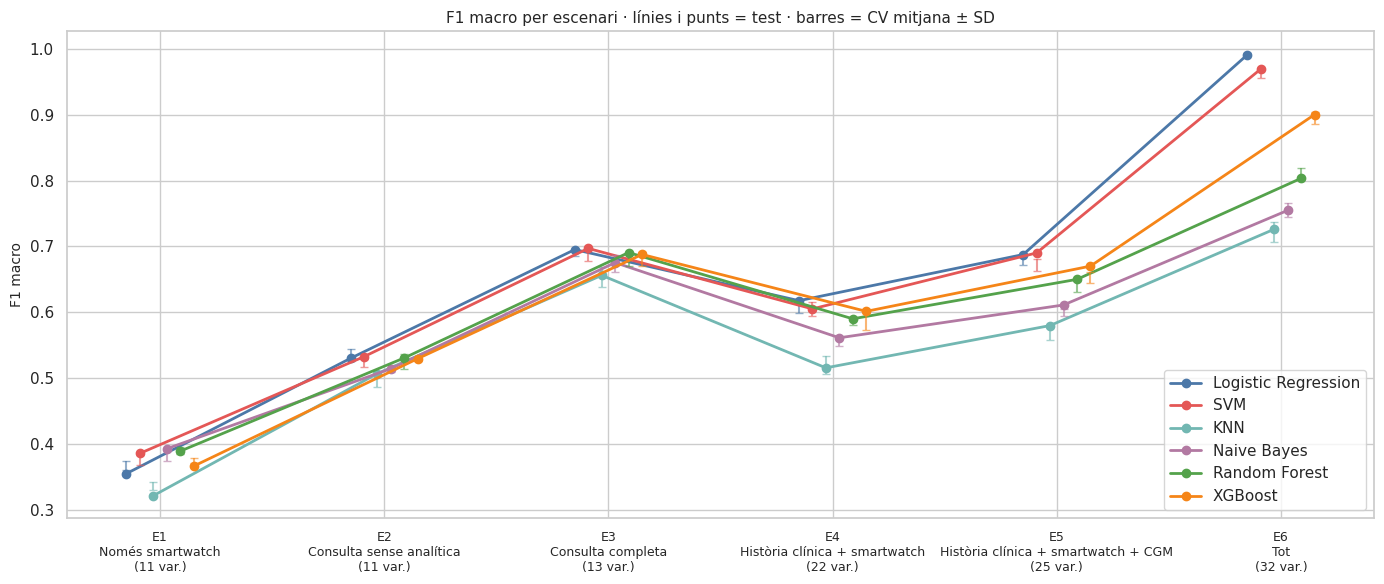

MILLOR MODEL DE CADA ESCENARI (triat per la validació creuada)


,Escenari,Nº var.,Millor model,F1 CV,F1 test,AUC test,Kappa ponderat,Sensib. Critical,Sensib. High
E1,Només smartwatch,11,Random Forest,0.3903 ± 0.0058,0.3894,0.6873,0.4393,0.283,0.287
E2,Consulta sense analítica,11,Logistic Regression,0.5352 ± 0.0097,0.5303,0.8193,0.6941,0.473,0.348
E3,Consulta completa,13,Logistic Regression,0.6896 ± 0.0044,0.6953,0.9121,0.8473,0.66,0.618
E4,Història clínica + smartwatch,22,Logistic Regression,0.6081 ± 0.0092,0.6177,0.8648,0.7798,0.577,0.487
E5,Història clínica + smartwatch + CGM,25,Logistic Regression,0.6797 ± 0.0077,0.6877,0.9056,0.8353,0.673,0.57
E6,Tot,32,Logistic Regression,0.9916 ± 0.0013,0.9909,0.9999,0.9963,0.997,0.985


In [15]:
ESC = [e for e in ESCENARIS if e in RES]
etiq_esc = [f"{e}\n{ESCENARIS[e]['nom']}\n({len(ESCENARIS[e]['vars'])} var.)" for e in ESC]

def matriu(fn):
    return pd.DataFrame({e: {m: fn(RES[e][m]) for m in RES[e]} for e in ESC}).reindex(list(MODELS))

F1_TEST = matriu(lambda r: r["test"]["F1-score"])
F1_CV   = matriu(lambda r: r["cv_val"]["F1-score"].mean())
F1_SD   = matriu(lambda r: r["cv_val"]["F1-score"].std(ddof=1))
REC_CRIT = matriu(lambda r: r["pc_test"].loc["Critical", "Recall (Sensitivity)"])
REC_HIGH = matriu(lambda r: r["pc_test"].loc["High", "Recall (Sensitivity)"])

print("F1 MACRO AL TEST (models × escenaris)"); display(F1_TEST.round(4))
print("F1 MACRO A LA VALIDACIÓ CREUADA (mitjana)"); display(F1_CV.round(4))

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
for ax, (M, t) in zip(axes, [(F1_TEST, "F1 macro (test)"), (REC_CRIT, "Sensibilitat Critical (test)"), (REC_HIGH, "Sensibilitat High (test)")]):
    sns.heatmap(M, annot=True, fmt=".3f", cmap="RdYlGn", vmin=max(0, np.nanmin(M.values) - 0.05), vmax=1,
                ax=ax, cbar=False, linewidths=0.5, xticklabels=ESC)
    ax.set_title(t); ax.set_ylabel("")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
xs = np.arange(len(ESC))
for i, m in enumerate(F1_TEST.index):
    off = (i - (len(F1_TEST) - 1) / 2) * 0.06
    ax.errorbar(xs + off, F1_CV.loc[m], yerr=F1_SD.loc[m], fmt="none", ecolor=COL_MODELS[m], alpha=0.6, capsize=3)
    ax.plot(xs + off, F1_TEST.loc[m], "-o", color=COL_MODELS[m], lw=2, label=m)
ax.set_xticks(xs); ax.set_xticklabels(etiq_esc, fontsize=9)
ax.set_ylabel("F1 macro"); ax.set_title("F1 macro per escenari · línies i punts = test · barres = CV mitjana ± SD")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

MILLORS = {}
for e in ESC:
    MILLORS[e] = max(RES[e], key=lambda k: RES[e][k]["cv_val"]["F1-score"].mean())
taula_millors = pd.DataFrame({e: {"Escenari": ESCENARIS[e]["nom"], "Nº var.": len(ESCENARIS[e]["vars"]), "Millor model": MILLORS[e],
                                  "F1 CV": f"{RES[e][MILLORS[e]]['cv_val']['F1-score'].mean():.4f} ± {RES[e][MILLORS[e]]['cv_val']['F1-score'].std(ddof=1):.4f}",
                                  "F1 test": round(RES[e][MILLORS[e]]["test"]["F1-score"], 4),
                                  "AUC test": round(RES[e][MILLORS[e]]["test"]["AUC"], 4),
                                  "Kappa ponderat": round(RES[e][MILLORS[e]]["test"]["Kappa ponderat"], 4),
                                  "Sensib. Critical": round(RES[e][MILLORS[e]]["pc_test"].loc["Critical", "Recall (Sensitivity)"], 3),
                                  "Sensib. High": round(RES[e][MILLORS[e]]["pc_test"].loc["High", "Recall (Sensitivity)"], 3)}
                             for e in ESC}).T
print("MILLOR MODEL DE CADA ESCENARI (triat per la validació creuada)"); display(taula_millors)

### Cel·la 16 · Comparacions clau amb interval de confiança (bootstrap aparellat)
Per a cada comparació (per exemple, E2 → E4) es calcula la **diferència** d'F1 macro i de sensibilitat de Critical **sobre els mateixos 3.000 pacients del test**. Es remostregen els pacients 1.000 vegades amb reposició i s'obté l'IC 95 % de la diferència.

**Com es llegeix:** Δ > 0 vol dir que el segon escenari és millor. Si l'IC 95 % **no inclou el 0**, la diferència és significativa (✔). Es fa per a cada model i per al millor model de cada escenari.

Al gràfic (*forest plot*), cada punt és la diferència del millor model i la barra és l'IC 95 %. La línia vertical és el 0 (cap diferència).


E2 → E3 · Quant aporta l'analítica de sang


,Comparació,Δ F1,IC95 F1,Sig. F1,Δ Sensib. Critical,IC95 Sensib. Critical,Sig. Sensib. Critical
Model,,,,,,,
Logistic Regression,E2 → E3,0.1650,"[+0.1418, +0.1870]",✔,0.1867,"[+0.1185, +0.2457]",✔
SVM,E2 → E3,0.1642,"[+0.1395, +0.1873]",✔,-0.0100,"[-0.0756, +0.0495]",
KNN,E2 → E3,0.1490,"[+0.1280, +0.1693]",✔,0.1233,"[+0.0769, +0.1718]",✔
Naive Bayes,E2 → E3,0.1609,"[+0.1385, +0.1818]",✔,0.2133,"[+0.1566, +0.2703]",✔
Random Forest,E2 → E3,0.1598,"[+0.1369, +0.1828]",✔,0.1467,"[+0.0839, +0.2033]",✔
XGBoost,E2 → E3,0.1579,"[+0.1337, +0.1788]",✔,0.1667,"[+0.1065, +0.2234]",✔
Millor model,E2 → E3,0.1650,"[+0.1418, +0.1870]",✔,0.1867,"[+0.1185, +0.2457]",✔



E2 → E4 · Quant aporta el smartwatch a la consulta (pregunta central)


,Comparació,Δ F1,IC95 F1,Sig. F1,Δ Sensib. Critical,IC95 Sensib. Critical,Sig. Sensib. Critical
Model,,,,,,,
Logistic Regression,E2 → E4,0.0874,"[+0.0678, +0.1065]",✔,0.1033,"[+0.0592, +0.1502]",✔
SVM,E2 → E4,0.0724,"[+0.0525, +0.0927]",✔,-0.1433,"[-0.1903, -0.0960]",✔
KNN,E2 → E4,0.0086,"[-0.0127, +0.0311]",,-0.0267,"[-0.0719, +0.0190]",
Naive Bayes,E2 → E4,0.0468,"[+0.0294, +0.0651]",✔,0.0967,"[+0.0528, +0.1396]",✔
Random Forest,E2 → E4,0.0592,"[+0.0403, +0.0784]",✔,0.0267,"[-0.0142, +0.0667]",
XGBoost,E2 → E4,0.0716,"[+0.0533, +0.0911]",✔,0.0967,"[+0.0528, +0.1429]",✔
Millor model,E2 → E4,0.0874,"[+0.0678, +0.1065]",✔,0.1033,"[+0.0592, +0.1502]",✔



E4 → E5 · Quant aporta el CGM


,Comparació,Δ F1,IC95 F1,Sig. F1,Δ Sensib. Critical,IC95 Sensib. Critical,Sig. Sensib. Critical
Model,,,,,,,
Logistic Regression,E4 → E5,0.0700,"[+0.0522, +0.0883]",✔,0.0967,"[+0.0470, +0.1410]",✔
SVM,E4 → E5,0.0850,"[+0.0676, +0.1026]",✔,0.1667,"[+0.1166, +0.2114]",✔
KNN,E4 → E5,0.0642,"[+0.0443, +0.0858]",✔,0.0600,"[+0.0100, +0.1108]",✔
Naive Bayes,E4 → E5,0.0498,"[+0.0349, +0.0654]",✔,0.0633,"[+0.0219, +0.1065]",✔
Random Forest,E4 → E5,0.0599,"[+0.0427, +0.0792]",✔,0.0833,"[+0.0429, +0.1238]",✔
XGBoost,E4 → E5,0.0686,"[+0.0495, +0.0884]",✔,0.0833,"[+0.0352, +0.1318]",✔
Millor model,E4 → E5,0.0700,"[+0.0522, +0.0883]",✔,0.0967,"[+0.0470, +0.1410]",✔


... (2 outputs left out)


E3 → E5 · Telemonitoratge sense sang vs visita amb analítica


,Comparació,Δ F1,IC95 F1,Sig. F1,Δ Sensib. Critical,IC95 Sensib. Critical,Sig. Sensib. Critical
Model,,,,,,,
Logistic Regression,E3 → E5,-0.0076,"[-0.0325, +0.0182]",,0.0133,"[-0.0609, +0.0882]",
SVM,E3 → E5,-0.0068,"[-0.0321, +0.0186]",,0.0333,"[-0.0364, +0.1046]",
KNN,E3 → E5,-0.0762,"[-0.0993, -0.0517]",✔,-0.0900,"[-0.1522, -0.0278]",✔
Naive Bayes,E3 → E5,-0.0643,"[-0.0874, -0.0395]",✔,-0.0533,"[-0.1182, +0.0137]",
Random Forest,E3 → E5,-0.0407,"[-0.0649, -0.0149]",✔,-0.0367,"[-0.1004, +0.0369]",
XGBoost,E3 → E5,-0.0177,"[-0.0415, +0.0077]",,0.0133,"[-0.0525, +0.0871]",
Millor model,E3 → E5,-0.0076,"[-0.0325, +0.0182]",,0.0133,"[-0.0609, +0.0882]",



E5 → E6 · Què afegeixen l'analítica i les variables dubtoses


,Comparació,Δ F1,IC95 F1,Sig. F1,Δ Sensib. Critical,IC95 Sensib. Critical,Sig. Sensib. Critical
Model,,,,,,,
Logistic Regression,E5 → E6,0.3032,"[+0.2848, +0.3225]",✔,0.3233,"[+0.2717, +0.3774]",✔
SVM,E5 → E6,0.2790,"[+0.2606, +0.2982]",✔,0.3133,"[+0.2598, +0.3668]",✔
KNN,E5 → E6,0.1462,"[+0.1244, +0.1669]",✔,0.1067,"[+0.0503, +0.1556]",✔
Naive Bayes,E5 → E6,0.1436,"[+0.1223, +0.1639]",✔,0.1433,"[+0.0854, +0.1979]",✔
Random Forest,E5 → E6,0.1534,"[+0.1302, +0.1776]",✔,0.0767,"[+0.0135, +0.1370]",✔
XGBoost,E5 → E6,0.2300,"[+0.2088, +0.2513]",✔,0.1900,"[+0.1200, +0.2518]",✔
Millor model,E5 → E6,0.3032,"[+0.2848, +0.3225]",✔,0.3233,"[+0.2717, +0.3774]",✔


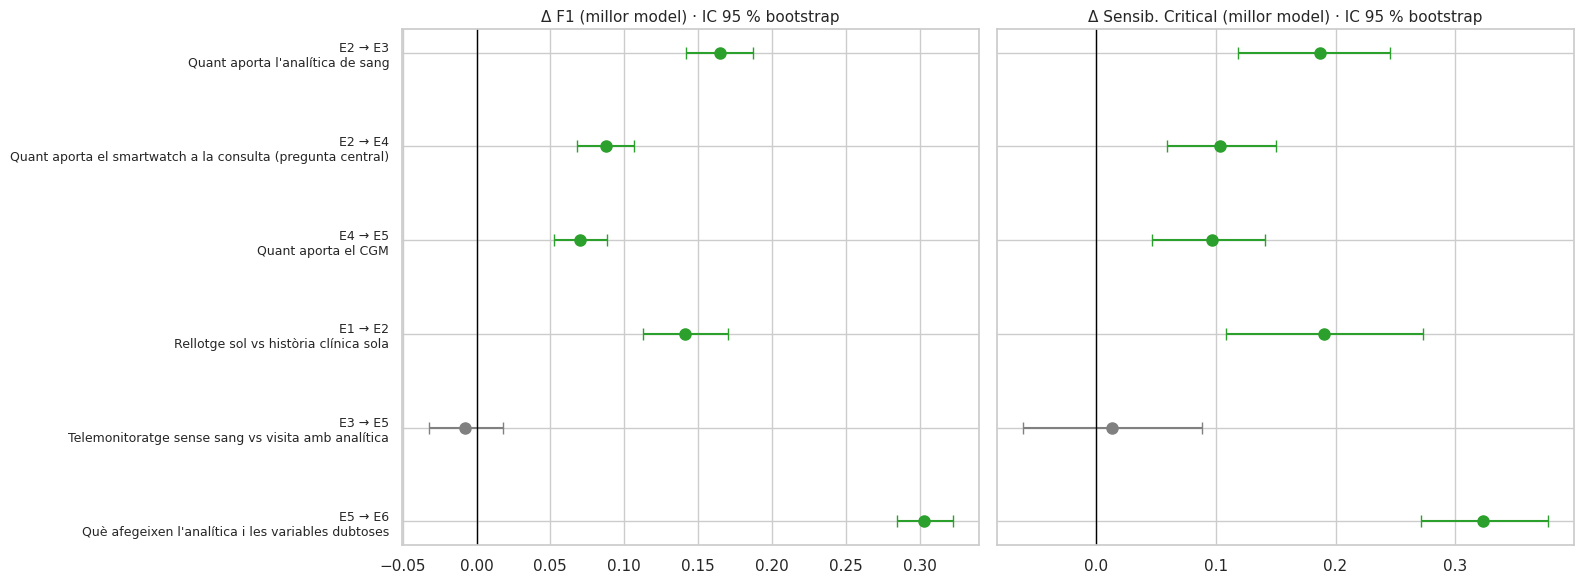

Verd = millora significativa · vermell = empitjora significativament · gris = diferència no significativa


In [16]:
COMPARACIONS = [("E2", "E3", "Quant aporta l'analítica de sang"),
                ("E2", "E4", "Quant aporta el smartwatch a la consulta (pregunta central)"),
                ("E4", "E5", "Quant aporta el CGM"),
                ("E1", "E2", "Rellotge sol vs història clínica sola"),
                ("E3", "E5", "Telemonitoratge sense sang vs visita amb analítica"),
                ("E5", "E6", "Què afegeixen l'analítica i les variables dubtoses")]
COMPARACIONS = [c for c in COMPARACIONS if c[0] in RES and c[1] in RES]

yt = np.asarray(y_test)
rng = np.random.default_rng(SEED)
IDX = rng.integers(0, len(yt), size=(N_BOOT, len(yt)))          # mateixos remostrejos per a totes les comparacions

def cm_batch(y, p, idx):                                        # matrius de confusió dels N_BOOT remostrejos alhora
    codi = y[idx] * 4 + p[idx]
    return np.stack([np.bincount(c, minlength=16) for c in codi]).reshape(-1, 4, 4)

def f1_i_recall(cms):
    tp = np.diagonal(cms, axis1=1, axis2=2).astype(float)
    pred, real = cms.sum(axis=1), cms.sum(axis=2)
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    rec = np.divide(tp, real, out=np.zeros_like(tp), where=real > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return f1.mean(axis=1), rec[:, 3]                           # F1 macro, sensibilitat Critical

def delta(pa, pb):
    full = np.arange(len(yt))[None, :]
    fa, ra = f1_i_recall(cm_batch(yt, pa, full)); fb, rb = f1_i_recall(cm_batch(yt, pb, full))
    ba_f, ba_r = f1_i_recall(cm_batch(yt, pa, IDX)); bb_f, bb_r = f1_i_recall(cm_batch(yt, pb, IDX))
    out = {}
    for nom, d, bd in (("F1", fb[0] - fa[0], bb_f - ba_f), ("Sensib. Critical", rb[0] - ra[0], bb_r - ba_r)):
        lo, hi = np.percentile(bd, [2.5, 97.5])
        out[nom] = (d, lo, hi, "✔" if lo > 0 or hi < 0 else "")
    return out

files = []
for a, b, preg in COMPARACIONS:
    parelles = [(m, RES[a][m]["pred_test"], RES[b][m]["pred_test"], m) for m in MODELS]
    parelles.append(("Millor model", RES[a][MILLORS[a]]["pred_test"], RES[b][MILLORS[b]]["pred_test"], f"{MILLORS[a]} → {MILLORS[b]}"))
    for m, pa, pb, detall in parelles:
        d = delta(np.asarray(pa), np.asarray(pb))
        files.append({"Comparació": f"{a} → {b}", "Pregunta": preg, "Model": m, "Detall": detall,
                      **{f"Δ {k}": v[0] for k, v in d.items()},
                      **{f"IC95 {k}": f"[{v[1]:+.4f}, {v[2]:+.4f}]" for k, v in d.items()},
                      **{f"Sig. {k}": v[3] for k, v in d.items()},
                      **{f"_lo {k}": v[1] for k, v in d.items()}, **{f"_hi {k}": v[2] for k, v in d.items()}})
DELTES = pd.DataFrame(files)
visibles = ["Comparació", "Model", "Δ F1", "IC95 F1", "Sig. F1", "Δ Sensib. Critical", "IC95 Sensib. Critical", "Sig. Sensib. Critical"]
for (a, b, preg) in COMPARACIONS:
    print(f"\n{a} → {b} · {preg}")
    display(DELTES[DELTES["Comparació"] == f"{a} → {b}"][visibles].round(4).set_index("Model"))

bm = DELTES[DELTES["Model"] == "Millor model"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 0.7 * len(bm) + 1.8), sharey=True)
for ax, k in zip(axes, ["F1", "Sensib. Critical"]):
    for i, r in bm.iterrows():
        col = "#2ca02c" if r[f"_lo {k}"] > 0 else ("#d62728" if r[f"_hi {k}"] < 0 else "grey")
        ax.errorbar(r[f"Δ {k}"], i, xerr=[[r[f"Δ {k}"] - r[f"_lo {k}"]], [r[f"_hi {k}"] - r[f"Δ {k}"]]],
                    fmt="o", color=col, capsize=4, ms=8)
    ax.axvline(0, color="black", lw=1); ax.set_title(f"Δ {k} (millor model) · IC 95 % bootstrap")
    ax.set_yticks(range(len(bm))); ax.set_yticklabels([f"{r['Comparació']}\n{r['Pregunta']}" for _, r in bm.iterrows()], fontsize=9)
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()
print("Verd = millora significativa · vermell = empitjora significativament · gris = diferència no significativa")

### Cel·la 17 · Resum automàtic de les conclusions
La cel·la redacta, amb els números obtinguts, una frase per a cada comparació clau (millor model de cada escenari). Serveix de base per a l'apartat de resultats de la memòria.

In [17]:
print("RESUM DE RESULTATS · millor model de cada escenari (triat per la CV), test amb IC 95 % bootstrap\n")
for e in ESC:
    r = RES[e][MILLORS[e]]
    print(f"• {e} · {ESCENARIS[e]['nom']} ({len(ESCENARIS[e]['vars'])} var.): {MILLORS[e]} · F1 = {r['test']['F1-score']:.3f} · "
          f"sensibilitat Critical = {r['pc_test'].loc['Critical', 'Recall (Sensitivity)']:.3f} · High = {r['pc_test'].loc['High', 'Recall (Sensitivity)']:.3f}")
print()
for _, r in bm.iterrows():
    sig = "és significativa" if r["Sig. F1"] else "NO és significativa"
    sentit = "millora" if r["Δ F1"] > 0 else "empitjora"
    print(f"• {r['Comparació']} ({r['Pregunta']}): l'F1 {sentit} {abs(r['Δ F1']):.3f} punts {r['IC95 F1']}, i la diferència {sig}. "
          f"Sensibilitat de Critical: Δ = {r['Δ Sensib. Critical']:+.3f} {r['IC95 Sensib. Critical']}.")

RESUM DE RESULTATS · millor model de cada escenari (triat per la CV), test amb IC 95 % bootstrap

• E1 · Només smartwatch (11 var.): Random Forest · F1 = 0.389 · sensibilitat Critical = 0.283 · High = 0.287
• E2 · Consulta sense analítica (11 var.): Logistic Regression · F1 = 0.530 · sensibilitat Critical = 0.473 · High = 0.348
• E3 · Consulta completa (13 var.): Logistic Regression · F1 = 0.695 · sensibilitat Critical = 0.660 · High = 0.618
• E4 · Història clínica + smartwatch (22 var.): Logistic Regression · F1 = 0.618 · sensibilitat Critical = 0.577 · High = 0.487
• E5 · Història clínica + smartwatch + CGM (25 var.): Logistic Regression · F1 = 0.688 · sensibilitat Critical = 0.673 · High = 0.570
• E6 · Tot (32 var.): Logistic Regression · F1 = 0.991 · sensibilitat Critical = 0.997 · High = 0.985

• E2 → E3 (Quant aporta l'analítica de sang): l'F1 millora 0.165 punts [+0.1418, +0.1870], i la diferència és significativa. Sensibilitat de Critical: Δ = +0.187 [+0.1185, +0.2457].
• E2 → 

### Cel·la 18 · Exportació dels resultats
Es desen en CSV (a la carpeta de resultats) per fer servir a la memòria i a la Llibreta 5.

In [18]:
files = []
for e in ESC:
    for m, r in RES[e].items():
        f = {"Escenari": e, "Nom escenari": ESCENARIS[e]["nom"], "Model": m, "Nº variables": len(ESCENARIS[e]["vars"])}
        for met in METRIQUES:
            f[f"{met} CV mitjana"] = r["cv_val"][met].mean(); f[f"{met} CV SD"] = r["cv_val"][met].std(ddof=1); f[f"{met} Test"] = r["test"][met]
        for cl in ETIQ:
            f[f"Sensibilitat {cl} Test"] = r["pc_test"].loc[cl, "Recall (Sensitivity)"]; f[f"F1 {cl} Test"] = r["pc_test"].loc[cl, "F1-score"]
        f["Hiperparàmetres"] = str({k.replace("model__", ""): v for k, v in r["params"].items()}); f["Temps (s)"] = r["temps_s"]
        files.append(f)
comp = pd.DataFrame(files)
comp.round(5).to_csv(os.path.join(CARPETA, "llibreta4_comparativa.csv"), index=False)
DELTES.drop(columns=[c for c in DELTES.columns if c.startswith("_")]).round(5).to_csv(os.path.join(CARPETA, "llibreta4_comparacions_bootstrap.csv"), index=False)
pd.DataFrame([{"Escenari": e, "Nom": d["nom"], "Variables": ", ".join(d["vars"])} for e, d in ESCENARIS.items()]).to_csv(
    os.path.join(CARPETA, "llibreta4_variables_escenaris.csv"), index=False)
print("Desats a", CARPETA, ": llibreta4_comparativa.csv · llibreta4_comparacions_bootstrap.csv · llibreta4_variables_escenaris.csv")

Desats a resultats_llibreta4 : llibreta4_comparativa.csv · llibreta4_comparacions_bootstrap.csv · llibreta4_variables_escenaris.csv


### Conclusions (per omplir després d'executar)
Preguntes guia per redactar-les, a partir de les cel·les 15 – 17:

1. **E1 vs E2:** amb el mateix nombre de variables, informa més el rellotge o la història clínica?
2. **E2 → E3:** quant depèn avui el triatge de tenir una analítica recent?
3. **E2 → E4 (pregunta central):** el smartwatch millora significativament el que ja sap el metge? I la sensibilitat de Critical?
4. **E4 → E5:** el CGM aporta una millora significativa?
5. **E3 vs E5:** el telemonitoratge sense sang s'acosta a una visita amb analítica?
6. **Models:** el millor model és el mateix a tots els escenaris? La Regressió Logística continua guanyant quan no hi ha analítica?
7. **Quin escenari es fa servir per al prototip de la Llibreta 5** (per defecte, E4: és el telemonitoratge més freqüent i el que no depèn de cap sensor finançat).

**Limitacions a recordar:** dataset sintètic i transversal (cada fila és un pacient en un sol moment); sense etiqueta de tipus de diabetis; l'assignació de variables a cada bloc és una decisió raonada, no una dada del dataset.